In [1]:
import os
import json
import csv
import re
from datetime import datetime

def extract_condition(notebook_path):
    try:
        with open(notebook_path, 'r') as f:
            data = json.load(f)
            notes = data.get('notes', [])
            filtered_notes = [
                note.strip() for note in notes
                if note.strip().lower() not in ['l', 'nl']
            ]
            condition = " | ".join(filtered_notes) if filtered_notes else "Unlabeled"
            return condition
    except Exception as e:
        print(f"[!] Error reading notebook.json: {notebook_path}: {e}")
        return "Unknown"

def extract_laser_status(stimlog_path):
    try:
        with open(stimlog_path, 'r') as f:
            data = json.load(f)
            laser_flags = [trial.get("LaserOnOff", 0) for trial in data]
            if any(flag == 1 for flag in laser_flags):
                return "ON"
            return "OFF"
    except Exception as e:
        print(f"[!] Error reading stimlog.json: {stimlog_path}: {e}")
        return "Unknown"

def parse_mouse_and_date(folder_name):
    """
    Extract mouse number and date from folder name like '2025-04-21_11-11-48_mouse-3355'
    """
    mouse_match = re.search(r'mouse[-_]?(\d+)', folder_name, re.IGNORECASE)
    date_match = re.match(r'(\d{4}-\d{2}-\d{2})', folder_name)
    
    mouse = mouse_match.group(1) if mouse_match else "Unknown"
    date_str = date_match.group(1) if date_match else "1900-01-01"

    # Use datetime object for accurate sorting
    try:
        date_obj = datetime.strptime(date_str, "%Y-%m-%d")
    except ValueError:
        date_obj = datetime(1900, 1, 1)

    return mouse, date_str, date_obj

def scan_subdirs_and_write_csv(parent_dir, output_csv):
    rows = []

    for session_folder in os.listdir(parent_dir):
        session_path = os.path.join(parent_dir, session_folder)
        if not os.path.isdir(session_path):
            continue

        # Look one level deeper
        subdirs = [d for d in os.listdir(session_path) if os.path.isdir(os.path.join(session_path, d))]
        for subdir in subdirs:
            subdir_path = os.path.join(session_path, subdir)

            notebook_path = os.path.join(subdir_path, 'notebook.json')
            stimlog_path = os.path.join(subdir_path, 'stimlog.json')

            if os.path.exists(notebook_path) and os.path.exists(stimlog_path):
                condition = extract_condition(notebook_path)
                laser_status = extract_laser_status(stimlog_path)
                folder_name = os.path.basename(subdir_path)

                mouse, date_str, date_obj = parse_mouse_and_date(folder_name)

                rows.append({
                    'Folder': folder_name,
                    'Mouse': mouse,
                    'Date': date_str,
                    'DateObj': date_obj,  # for sorting
                    'Condition': condition,
                    'Laser': laser_status
                })

    # Sort by Mouse → Date
    rows.sort(key=lambda x: (x['Mouse'], x['DateObj']))

    # Write CSV
    if rows:
        with open(output_csv, 'w', newline='') as csvfile:
            fieldnames = ['Folder', 'Mouse', 'Date', 'Condition', 'Laser']
            writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
            writer.writeheader()
            for row in rows:
                # Drop 'DateObj' before writing
                row.pop('DateObj', None)
                writer.writerow(row)

        print(f"\n✅ CSV written to: {output_csv} ({len(rows)} entries)")
    else:
        print("\n⚠️ No valid data found. CSV not created.")

# Example usage
# if __name__ == "__main__":
#     parent_directory = "/Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/"  # ← CHANGE THIS
#     output_csv = "/Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/conditions_summary.csv"
#     scan_subdirs_and_write_csv(parent_directory, output_csv)


In [1]:
import os
import json
import csv
import re
import cv2
from datetime import datetime

def extract_condition(notebook_path):
    try:
        with open(notebook_path, 'r') as f:
            data = json.load(f)
            notes = data.get('notes', [])
            filtered_notes = [
                note.strip() for note in notes
                if note.strip().lower() not in ['l', 'nl']
            ]
            condition = " | ".join(filtered_notes) if filtered_notes else "Unlabeled"
            return condition
    except Exception as e:
        print(f"[!] Error reading notebook.json: {notebook_path}: {e}")
        return "Unknown"

def extract_laser_status(stimlog_path):
    try:
        with open(stimlog_path, 'r') as f:
            data = json.load(f)
            laser_flags = [trial.get("LaserOnOff", 0) for trial in data]
            return "ON" if any(flag == 1 for flag in laser_flags) else "OFF"
    except Exception as e:
        print(f"[!] Error reading stimlog.json: {stimlog_path}: {e}")
        return "Unknown"

def parse_mouse_and_date(folder_name):
    """
    Extract mouse number and datetime from folder name like '2025-04-21_11-11-48_mouse-3355'
    """
    mouse_match = re.search(r'mouse[-_]?(\d+)', folder_name, re.IGNORECASE)
    datetime_match = re.match(r'(\d{4}-\d{2}-\d{2})_(\d{2}-\d{2}-\d{2})', folder_name)

    mouse = mouse_match.group(1) if mouse_match else "Unknown"
    
    if datetime_match:
        date_str = datetime_match.group(1)
        time_str = datetime_match.group(2).replace("-", ":")
        datetime_str = f"{date_str} {time_str}"
        try:
            date_obj = datetime.strptime(datetime_str, "%Y-%m-%d %H:%M:%S")
        except ValueError:
            date_obj = datetime(1900, 1, 1)
    else:
        date_str = "1900-01-01"
        date_obj = datetime(1900, 1, 1)

    return mouse, date_str, date_obj

def get_video_stats(folder_path):
    try:
        for file in os.listdir(folder_path):
            if file.lower().endswith('.mp4'):
                video_path = os.path.join(folder_path, file)
                cap = cv2.VideoCapture(video_path)
                if not cap.isOpened():
                    return None, None
                
                frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
                fps = cap.get(cv2.CAP_PROP_FPS)
                duration = frames / fps if fps > 0 else 0

                cap.release()
                return frames, round(duration, 2)
    except Exception as e:
        print(f"[!] Error reading video in {folder_path}: {e}")
    
    return None, None

def scan_subdirs_and_write_csv(parent_dir, output_csv):
    rows = []

    for session_folder in os.listdir(parent_dir):
        session_path = os.path.join(parent_dir, session_folder)
        if not os.path.isdir(session_path):
            continue

        subdirs = [d for d in os.listdir(session_path) if os.path.isdir(os.path.join(session_path, d))]
        for subdir in subdirs:
            subdir_path = os.path.join(session_path, subdir)

            notebook_path = os.path.join(subdir_path, 'notebook.json')
            stimlog_path = os.path.join(subdir_path, 'stimlog.json')

            if os.path.exists(notebook_path) and os.path.exists(stimlog_path):
                condition = extract_condition(notebook_path)
                laser_status = extract_laser_status(stimlog_path)
                folder_name = os.path.basename(subdir_path)

                mouse, date_str, date_obj = parse_mouse_and_date(folder_name)
                frames, duration = get_video_stats(subdir_path)

                rows.append({
                    'Folder': folder_name,
                    'Mouse': mouse,
                    'Date': date_str,
                    'DateObj': date_obj,  # for sorting
                    'Condition': condition,
                    'Laser': laser_status,
                    'Frames': frames if frames is not None else "N/A",
                    'Duration_sec': duration if duration is not None else "N/A"
                })

    # Sort chronologically by mouse and datetime
    rows.sort(key=lambda x: (x['Mouse'], x['DateObj']))

    if rows:
        with open(output_csv, 'w', newline='') as csvfile:
            fieldnames = ['Folder', 'Mouse', 'Date', 'Condition', 'Laser', 'Frames', 'Duration_sec']
            writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
            writer.writeheader()
            for row in rows:
                row.pop('DateObj', None)  # Remove internal field
                writer.writerow(row)

        print(f"\n✅ CSV written to: {output_csv} ({len(rows)} entries)")
    else:
        print("\n⚠️ No valid data found. CSV not created.")

# Example usage
if __name__ == "__main__":
    parent_directory = "/Volumes/Projects/PreyCapture/ZI_A1Activation/"  # ← CHANGE THIS
    output_csv = "/Volumes/Projects/PreyCapture/ZI_A1Activation/conditions_summary.csv"
    scan_subdirs_and_write_csv(parent_directory, output_csv)


[!] Error reading stimlog.json: /Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/2025-04-25_12-59-35_mouse-3356/2025-04-25_12-59-37_mouse-3356/stimlog.json: 'str' object has no attribute 'get'
[!] Error reading stimlog.json: /Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/2025-04-26_13-07-16_mouse-3355/2025-04-26_13-07-20_mouse-3355/stimlog.json: 'str' object has no attribute 'get'
[!] Error reading stimlog.json: /Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/2025-05-15_21-56-32_mouse-3353/2025-05-15_21-56-35_mouse-3353/stimlog.json: 'str' object has no attribute 'get'

✅ CSV written to: /Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/conditions_summary.csv (1439 entries)


In [192]:
import os
import csv
import cv2
from tqdm import tqdm

FIXED_FPS = 200

def find_first_mp4(folder_path):
    try:
        for file in os.listdir(folder_path):
            if file.lower().endswith(".mp4"):
                return os.path.join(folder_path, file)
    except Exception as e:
        print(f"[!] Error accessing folder {folder_path}: {e}")
    return None

def get_video_stats_fixed_fps(video_path, fixed_fps=200):
    try:
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            return None, None
        frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        duration = frames / fixed_fps
        cap.release()
        return frames, round(duration, 2)
    except Exception as e:
        print(f"[!] Error reading video: {video_path}: {e}")
        return None, None

def update_csv_with_fixed_fps_video_lengths(existing_csv, parent_dir, updated_csv):
    updated_rows = []

    # Build a dict: folder_name -> list of full paths where that folder exists
    print("Scanning all directories under parent_dir once and building lookup dictionary...")
    folder_lookup = {}
    for root, dirs, _ in tqdm(os.walk(parent_dir), desc="Walking parent_dir"):
        for d in dirs:
            folder_lookup.setdefault(d, []).append(os.path.join(root, d))
    print(f"Found {len(folder_lookup)} unique folder names.\n")

    with open(existing_csv, 'r') as infile:
        reader = list(csv.DictReader(infile))
        fieldnames = reader[0].keys()
        if 'Frames' not in fieldnames:
            fieldnames = list(fieldnames) + ['Frames', 'Duration_sec']

        print(f"Processing {len(reader)} entries...")

        for row in tqdm(reader, desc="Folders processed", unit="folder"):
            target_folder = row['Folder']
            found = False

            # Lookup all paths with this folder name
            paths = folder_lookup.get(target_folder, [])

            for subdir_path in paths:
                parent_path = os.path.dirname(subdir_path)

                video_path = find_first_mp4(parent_path)
                if video_path and os.path.exists(video_path):
                    frames, duration = get_video_stats_fixed_fps(video_path, FIXED_FPS)
                    row['Frames'] = frames if frames is not None else "N/A"
                    row['Duration_sec'] = duration if duration is not None else "N/A"
                    tqdm.write(f"Found video for {target_folder}: {os.path.basename(video_path)} "
                               f"(Frames: {row['Frames']}, Duration: {row['Duration_sec']}s)")
                    found = True
                    break

            if not found:
                tqdm.write(f"[!] Could not find video folder or mp4 for: {target_folder}")
                row['Frames'] = "N/A"
                row['Duration_sec'] = "N/A"

            updated_rows.append(row)

    with open(updated_csv, 'w', newline='') as outfile:
        writer = csv.DictWriter(outfile, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(updated_rows)

    print(f"\n✅ Updated CSV written to: {updated_csv} ({len(updated_rows)} entries)")


In [14]:
if __name__ == "__main__":
    existing_csv = "/Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/conditions_summary.csv"
    parent_directory = "/Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/"
    updated_csv = "/Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/conditions_summary_with_lengths.csv"

    update_csv_with_fixed_fps_video_lengths(existing_csv, parent_directory, updated_csv)


Scanning all directories under parent_dir once and building lookup dictionary...


Walking parent_dir: 30948it [20:51, 24.72it/s]


Found 2823 unique folder names.

Processing 1439 entries...


Folders processed:   0%|                                                      | 1/1439 [00:00<13:46,  1.74folder/s]

Found video for 2025-04-24_14-56-19_mouse-3277: Sky_mouse-3356_2025-04-24T14_56_19.mp4 (Frames: 50120, Duration: 250.6s)


Folders processed:   0%|                                                      | 2/1439 [00:00<10:57,  2.19folder/s]

... (2,609 outputs left out)

Folders processed: 100%|██████████████████████████████████████████████████▉| 1438/1439 [07:44<00:00,  3.81folder/s]

Found video for 2025-05-16_23-09-52_mouse-3356: Sky_mouse-3356_2025-05-16T23_09_49.mp4 (Frames: 25320, Duration: 126.6s)


Folders processed: 100%|███████████████████████████████████████████████████| 1439/1439 [07:44<00:00,  3.10folder/s]


Found video for 2025-05-16_23-13-16_mouse-3356: Sky_mouse-3356_2025-05-16T23_13_15.mp4 (Frames: 25359, Duration: 126.8s)

✅ Updated CSV written to: /Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/conditions_summary_with_lengths.csv (1439 entries)


In [89]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your updated CSV
csv_path = "/Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/conditions_summary_with_lengths.csv"
df = pd.read_csv(csv_path)

# Show first few rows
print(df.head())

                           Folder  Mouse        Date            Condition  \
0  2025-04-24_14-56-19_mouse-3277   3277  2025-04-24            Unlabeled   
1  2025-03-31_11-39-35_mouse-3352   3352  2025-03-31  habituation | light   
2  2025-03-31_11-51-00_mouse-3352   3352  2025-03-31   habituation | dark   
3  2025-04-07_13-33-13_mouse-3352   3352  2025-04-07   habituation | dark   
4  2025-04-07_13-43-27_mouse-3352   3352  2025-04-07   habituation | dark   

  Laser    Frames  Duration_sec  
0   OFF   50120.0        250.60  
1   OFF  134547.0        672.74  
2   OFF  124663.0        623.32  
3   OFF  121629.0        608.14  
4   OFF  121867.0        609.34  


In [145]:
# import pandas as pd
import re

# Load your CSV
csv_path = "/Volumes/Projects/PreyCapture/ZIActivation/ViralChR2_Activation/conditions_summary_with_lengths.csv"
df = pd.read_csv(csv_path)

# Extract mouse number using regex (looks for 'mouse-1234' or 'mouse_1234')
df['Mouse'] = df['Folder'].str.extract(r'mouse[-_]?(\d+)', expand=False)

# Optional: convert to numeric
df['Mouse'] = pd.to_numeric(df['Mouse'], errors='coerce')

# Preview result
print(df[['Folder', 'Mouse']].head())


                           Folder  Mouse
0  2025-04-24_14-56-19_mouse-3277   3277
1  2025-03-31_11-39-35_mouse-3352   3352
2  2025-03-31_11-51-00_mouse-3352   3352
3  2025-04-07_13-33-13_mouse-3352   3352
4  2025-04-07_13-43-27_mouse-3352   3352


In [146]:
# Ensure 'Date' is datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Extract just the date (no time component) to group by day
df['DateOnly'] = df['Date'].dt.date

# Determine which dates are full baseline (Laser == 'OFF' for all rows that day)
baseline_dates = df.groupby('DateOnly')['Laser'].apply(lambda x: int(all(x == 'OFF')))

# Map the result back to each row
df['Baseline'] = df['DateOnly'].map(baseline_dates)

# Drop the helper column if you don't want it
df.drop(columns='DateOnly', inplace=True)

# Preview
print(df[['Date', 'Laser', 'Baseline']].head(10))


        Date Laser  Baseline
0 2025-04-24   OFF         0
1 2025-03-31   OFF         1
2 2025-03-31   OFF         1
3 2025-04-07   OFF         1
4 2025-04-07   OFF         1
5 2025-04-08   OFF         1
6 2025-04-08   OFF         1
7 2025-04-08   OFF         1
8 2025-04-08   OFF         1
9 2025-04-08   OFF         1


In [147]:
import pandas as pd

# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Normalize and simplify 'Condition'
df['Condition'] = df['Condition'].str.lower().str.strip()
df['ConditionCategory'] = df['Condition'].map({
    'pc | light': 'pc_light',
    'pc | dark': 'pc_dark'
})

# Initialize Day column
df['Day'] = None

# Define the groups of interest
group_conditions = [
    {'baseline': 1, 'condition': 'pc_light'},
    {'baseline': 1, 'condition': 'pc_dark'},
    {'baseline': 0, 'condition': 'pc_light'},
    {'baseline': 0, 'condition': 'pc_dark'},
]

# Assign Day numbers for all matching dates, per group
for cond in group_conditions:
    mask = (df['Baseline'] == cond['baseline']) & (df['ConditionCategory'] == cond['condition'])
    
    # Get all unique dates for this group, sorted
    unique_dates = sorted(df.loc[mask, 'Date'].dt.date.unique())
    
    # Create date → day number mapping
    date_to_day = {date: i + 1 for i, date in enumerate(unique_dates)}
    
    # Assign day number to matching rows
    df.loc[mask, 'Day'] = df.loc[mask, 'Date'].dt.date.map(date_to_day)

# Convert to integer
df['Day'] = pd.to_numeric(df['Day'], errors='coerce')

# Preview results
print(df[['Date', 'ConditionCategory', 'Baseline', 'Day']].dropna().sort_values(by=['ConditionCategory', 'Baseline', 'Day']).head(20))


          Date ConditionCategory  Baseline  Day
181 2025-04-28           pc_dark         0  1.0
182 2025-04-28           pc_dark         0  1.0
183 2025-04-28           pc_dark         0  1.0
184 2025-04-28           pc_dark         0  1.0
185 2025-04-28           pc_dark         0  1.0
186 2025-04-28           pc_dark         0  1.0
187 2025-04-28           pc_dark         0  1.0
188 2025-04-28           pc_dark         0  1.0
189 2025-04-28           pc_dark         0  1.0
190 2025-04-28           pc_dark         0  1.0
540 2025-04-28           pc_dark         0  1.0
541 2025-04-28           pc_dark         0  1.0
542 2025-04-28           pc_dark         0  1.0
543 2025-04-28           pc_dark         0  1.0
544 2025-04-28           pc_dark         0  1.0
545 2025-04-28           pc_dark         0  1.0
546 2025-04-28           pc_dark         0  1.0
547 2025-04-28           pc_dark         0  1.0
548 2025-04-28           pc_dark         0  1.0
549 2025-04-28           pc_dark        

In [148]:
# Define a function to modify ConditionCategory based on Baseline and Day
def modify_condition(row):
    if row['Baseline'] == 0 and 1 <= row['Day'] <= 5:
        return f"{row['ConditionCategory']}_6.3"
    elif row['Baseline'] == 0 and 6 <= row['Day'] <= 10:
        return f"{row['ConditionCategory']}_3.5"
    else:
        return row['ConditionCategory']

# Apply function row-wise
df['ConditionCategory'] = df.apply(modify_condition, axis=1)






In [149]:
df

,Folder,Mouse,Date,Condition,Laser,Frames,Duration_sec,Baseline,ConditionCategory,Day
0,2025-04-24_14-56-19_mouse-3277,3277,2025-04-24,unlabeled,OFF,50120.0,250.60,0,NaN,NaN
1,2025-03-31_11-39-35_mouse-3352,3352,2025-03-31,habituation | light,OFF,134547.0,672.74,1,NaN,NaN
2,2025-03-31_11-51-00_mouse-3352,3352,2025-03-31,habituation | dark,OFF,124663.0,623.32,1,NaN,NaN
3,2025-04-07_13-33-13_mouse-3352,3352,2025-04-07,habituation | dark,OFF,121629.0,608.14,1,NaN,NaN
4,2025-04-07_13-43-27_mouse-3352,3352,2025-04-07,habituation | dark,OFF,121867.0,609.34,1,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1434,2025-05-16_23-00-17_mouse-3356,3356,2025-05-16,pc | dark,OFF,14812.0,74.06,0,pc_dark_3.5,10.0
1435,2025-05-16_23-02-49_mouse-3356,3356,2025-05-16,pc | dark,ON,37897.0,189.49,0,pc_dark_3.5,10.0
1436,2025-05-16_23-06-49_mouse-3356,3356,2025-05-16,pc | dark,OFF,19366.0,96.83,0,pc_dark_3.5,10.0
1437,2025-05-16_23-09-52_mouse-3356,3356,2025-05-16,pc | dark,ON,25320.0,126.60,0,pc_dark_3.5,10.0


In [150]:
# Copy DataFrame to avoid overwriting original, if needed
test_df = df.copy()

# Baseline == 1
# Exclude rows with 'habituation' or 'exp' in Condition (case-insensitive)
baseline_mask = (
    (test_df['Baseline'] == 1) &
    (~test_df['Condition'].str.contains('habituation', case=False, na=False)) &
    (~test_df['Condition'].str.contains('exp', case=False, na=False))
)

# Set baseline_l for conditions containing 'light'
test_df.loc[
    baseline_mask & test_df['Condition'].str.contains('light', case=False, na=False),
    'ConditionCategory'
] = 'baseline_l'

# Set baseline_d for conditions containing 'dark'
test_df.loc[
    baseline_mask & test_df['Condition'].str.contains('dark', case=False, na=False),
    'ConditionCategory'
] = 'baseline_d'


In [151]:
def reset_days_by_earliest_date(df):
    df = df.copy()
    df['Date'] = pd.to_datetime(df['Date'])

    def assign_days(sub_df):
        unique_dates = sorted(sub_df['Date'].unique())
        date_to_day = {date: day+1 for day, date in enumerate(unique_dates)}
        # Create a new Day column for the subset
        return sub_df.assign(Day=sub_df['Date'].map(date_to_day))

    # Use transform to preserve all rows and just replace the Day column
    df['Day'] = (
        df.groupby('ConditionCategory', dropna=True)
          .apply(assign_days)
          .sort_index()['Day']
    )
    return df


In [152]:
test_df = reset_days_by_earliest_date(test_df)

/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_64407/483729755.py:13: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)
  df.groupby('ConditionCategory', dropna=True)


In [123]:
test_df

,Folder,Mouse,Date,Condition,Laser,Frames,Duration_sec,Baseline,ConditionCategory,Day
0,2025-04-24_14-56-19_mouse-3277,3277,2025-04-24,unlabeled,OFF,50120.0,250.60,0,NaN,NaN
1,2025-03-31_11-39-35_mouse-3352,3352,2025-03-31,habituation | light,OFF,134547.0,672.74,1,NaN,NaN
2,2025-03-31_11-51-00_mouse-3352,3352,2025-03-31,habituation | dark,OFF,124663.0,623.32,1,NaN,NaN
3,2025-04-07_13-33-13_mouse-3352,3352,2025-04-07,habituation | dark,OFF,121629.0,608.14,1,NaN,NaN
4,2025-04-07_13-43-27_mouse-3352,3352,2025-04-07,habituation | dark,OFF,121867.0,609.34,1,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1434,2025-05-16_23-00-17_mouse-3356,3356,2025-05-16,pc | dark,OFF,14812.0,74.06,0,pc_dark_3.5,5.0
1435,2025-05-16_23-02-49_mouse-3356,3356,2025-05-16,pc | dark,ON,37897.0,189.49,0,pc_dark_3.5,5.0
1436,2025-05-16_23-06-49_mouse-3356,3356,2025-05-16,pc | dark,OFF,19366.0,96.83,0,pc_dark_3.5,5.0
1437,2025-05-16_23-09-52_mouse-3356,3356,2025-05-16,pc | dark,ON,25320.0,126.60,0,pc_dark_3.5,5.0


In [97]:
df

,Folder,Mouse,Date,Condition,Laser,Frames,Duration_sec,Baseline,ConditionCategory,Day
0,2025-04-24_14-56-19_mouse-3277,3277,2025-04-24,unlabeled,OFF,50120.0,250.60,0,NaN,NaN
1,2025-03-31_11-39-35_mouse-3352,3352,2025-03-31,habituation | light,OFF,134547.0,672.74,1,NaN,NaN
2,2025-03-31_11-51-00_mouse-3352,3352,2025-03-31,habituation | dark,OFF,124663.0,623.32,1,NaN,NaN
3,2025-04-07_13-33-13_mouse-3352,3352,2025-04-07,habituation | dark,OFF,121629.0,608.14,1,NaN,NaN
4,2025-04-07_13-43-27_mouse-3352,3352,2025-04-07,habituation | dark,OFF,121867.0,609.34,1,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1434,2025-05-16_23-00-17_mouse-3356,3356,2025-05-16,pc | dark,OFF,14812.0,74.06,0,pc_dark_3.5,10.0
1435,2025-05-16_23-02-49_mouse-3356,3356,2025-05-16,pc | dark,ON,37897.0,189.49,0,pc_dark_3.5,10.0
1436,2025-05-16_23-06-49_mouse-3356,3356,2025-05-16,pc | dark,OFF,19366.0,96.83,0,pc_dark_3.5,10.0
1437,2025-05-16_23-09-52_mouse-3356,3356,2025-05-16,pc | dark,ON,25320.0,126.60,0,pc_dark_3.5,10.0


In [162]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from scipy.stats import sem

def plot_duration(df_subset, title):
    # Filter to keep only rows where ConditionLabel contains 'pc' (case-insensitive)
    df_subset = df_subset[df_subset['ConditionLabel'].str.contains('pc', case=False, na=False)]

    palette = {
        'PC + Light': 'orange',
        'PC + Dark': 'purple'
    }

    # Calculate mean and SEM across mice for each Condition and Day
    summary = (
        df_subset
        .groupby(['ConditionLabel', 'Day', 'Mouse'])
        ['Duration_sec']
        .median()
        .reset_index()
        .groupby(['ConditionLabel', 'Day'])
        .agg(
            mean_duration=('Duration_sec', 'mean'),
            sem_duration=('Duration_sec', sem)
        )
        .reset_index()
    )

    # Median per mouse for dots
    mouse_medians = (
        df_subset
        .groupby(['ConditionLabel', 'Mouse', 'Day'], as_index=False)['Duration_sec']
        .median()
    )

    plt.figure(figsize=(10,6))

    # Plot lines with error bars
    for condition, color in palette.items():
        cond_summary = summary[summary['ConditionLabel'] == condition]
        plt.errorbar(
            cond_summary['Day'],
            cond_summary['mean_duration'],
            yerr=cond_summary['sem_duration'],
            label=condition,
            color=color,
            lw=2.5,
            marker='o',
            capsize=4,
            markersize=8
        )

    # Plot mouse dots with alpha
    for condition, color in palette.items():
        subset = mouse_medians[mouse_medians['ConditionLabel'] == condition]
        plt.scatter(subset['Day'], subset['Duration_sec'], color=color, alpha=0.4, s=70)

    plt.title(title, fontsize=16)
    plt.xlabel("Day")
    plt.ylabel("Video Duration (seconds)")

    # Custom legend with mouse/trial counts
    legend_handles = []
    for condition, color in palette.items():
        cond_subset = df_subset[df_subset['ConditionLabel'] == condition]
        n_mice = cond_subset['Mouse'].nunique()
        n_trials = len(cond_subset)
        label = f"{condition} (Mice: {n_mice}, Trials: {n_trials})"
        patch = mpatches.Patch(color=color, label=label)
        legend_handles.append(patch)

    plt.legend(handles=legend_handles, title="Condition")
    plt.tight_layout()
    plt.show()


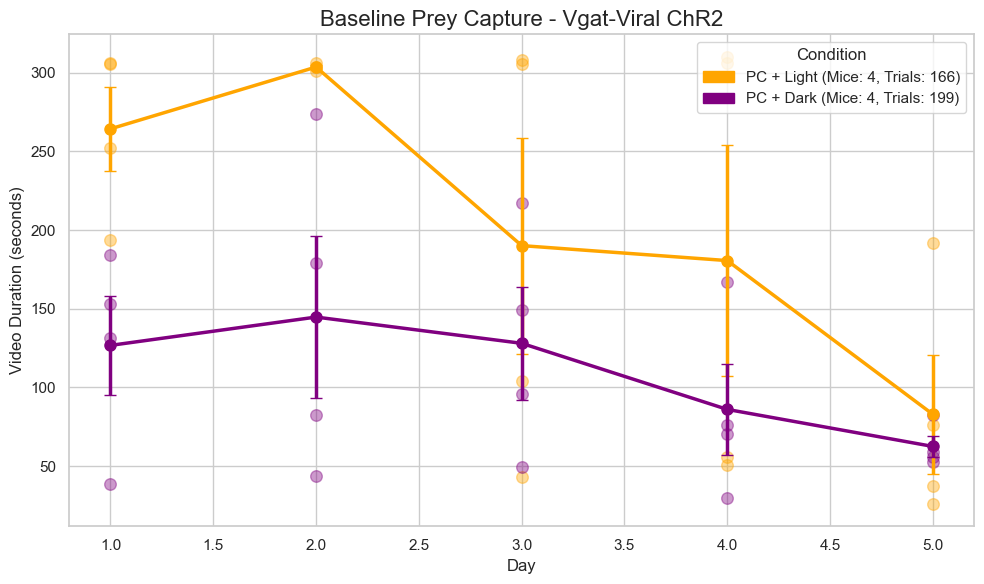

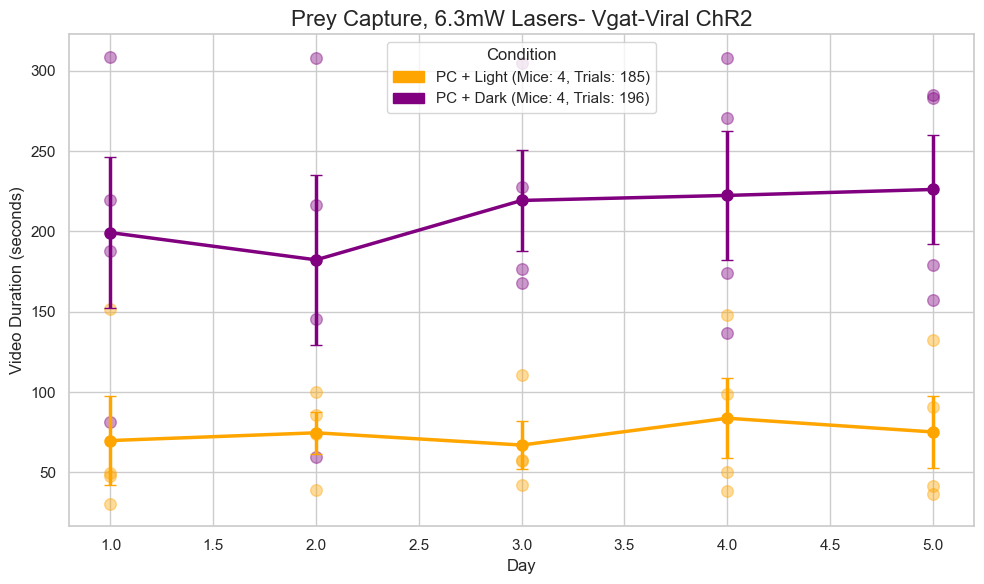

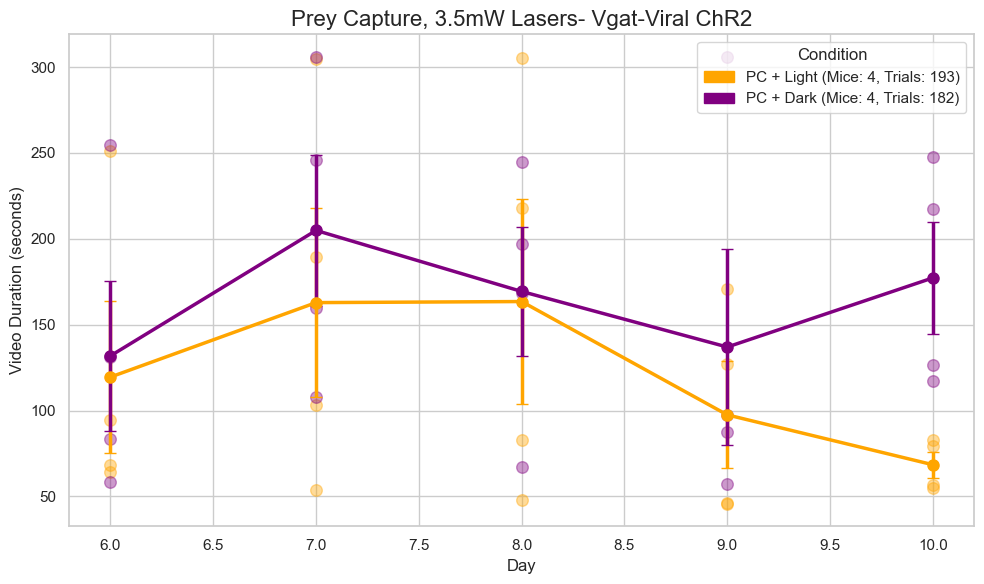

In [163]:
plot_duration(plot_df[plot_df['Baseline'] == 1], "Baseline Prey Capture - Vgat-Viral ChR2")
plot_duration(plot_df[(plot_df['Baseline'] == 0) & (plot_df['Day'].between(1,5))], "Prey Capture, 6.3mW Lasers- Vgat-Viral ChR2")
plot_duration(plot_df[(plot_df['Baseline'] == 0) & (plot_df['Day'].between(6,10))], "Prey Capture, 3.5mW Lasers- Vgat-Viral ChR2")


In [164]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.stats import sem

def plot_duration_comparison(df_subset, title_base):
    # Include baseline_l and baseline_d plus all rows where ConditionCategory contains 'pc' (case-insensitive)
    df_subset = df_subset[
        df_subset['ConditionCategory'].isin(['baseline_l', 'baseline_d']) |
        df_subset['ConditionCategory'].str.contains('pc', case=False, na=False)
    ]
    # Colors
    baseline_palette = {
        'baseline_l': 'orange',
        'baseline_d': 'purple'
    }
    laser_palette = {
        'ON': 'blue',
        'OFF': 'grey'
    }
    
    # === Helper to plot summary lines and points ===
    def plot_summary(ax, sub_df, group_col, palette_map, title):
        # Calculate mean and SEM of median durations across mice per day and group_col
        summary = (
            sub_df
            .groupby([group_col, 'Day', 'Mouse'])['Duration_sec']
            .median()
            .reset_index()
            .groupby([group_col, 'Day'])
            .agg(
                mean_duration=('Duration_sec', 'mean'),
                sem_duration=('Duration_sec', sem)
            )
            .reset_index()
        )

        mouse_medians = (
            sub_df
            .groupby([group_col, 'Mouse', 'Day'], as_index=False)['Duration_sec']
            .median()
        )

        for condition, color in palette_map.items():
            cond_summary = summary[summary[group_col] == condition]
            ax.errorbar(
                cond_summary['Day'],
                cond_summary['mean_duration'],
                yerr=cond_summary['sem_duration'],
                label=condition,
                color=color,
                lw=2.5,
                marker='o',
                capsize=4,
                markersize=8
            )
            subset = mouse_medians[mouse_medians[group_col] == condition]
            ax.scatter(subset['Day'], subset['Duration_sec'], color=color, alpha=0.4, s=70)

        ax.set_title(title, fontsize=14)
        ax.set_xlabel("Day")
        ax.set_ylabel("Video Duration (seconds)")
        ax.set_xticks(range(1, 6))
        ax.legend()

    # --- 1. Plot baseline (baseline_l vs baseline_d) ---
    baseline_df = df_subset[df_subset['ConditionCategory'].isin(['baseline_l', 'baseline_d'])]

    plt.figure(figsize=(8,6))
    ax = plt.gca()
    plot_summary(
        ax,
        baseline_df,
        group_col='ConditionCategory',
        palette_map=baseline_palette,
        title=f"{title_base} - Baseline Light vs Dark"
    )
    plt.tight_layout()
    plt.show()

    # --- 2. Plot laser ON/OFF for each power with separate subplots for light and dark ---
    power_levels = ['3.5', '6.3']

    for power in power_levels:
        power_df = df_subset[df_subset['ConditionCategory'].str.endswith(f"_{power}", na=False)]
        if power_df.empty:
            print(f"No data for power {power} mW")
            continue

        # Separate light vs dark based on ConditionCategory string
        light_df = power_df[power_df['ConditionCategory'].str.contains('light', case=False, na=False)]
        dark_df = power_df[power_df['ConditionCategory'].str.contains('dark', case=False, na=False)]

        fig, axs = plt.subplots(1, 2, figsize=(14,6), sharey=True)
        fig.suptitle(f"{title_base} - Laser {power} mW ON vs OFF", fontsize=16)

        # For light: group by Laser column ('ON'/'OFF')
        if not light_df.empty:
            plot_summary(
                axs[0],
                light_df,
                group_col='Laser',
                palette_map=laser_palette,
                title='Light Condition'
            )
        else:
            axs[0].set_visible(False)

        # For dark: group by Laser column ('ON'/'OFF')
        if not dark_df.empty:
            plot_summary(
                axs[1],
                dark_df,
                group_col='Laser',
                palette_map=laser_palette,
                title='Dark Condition'
            )
        else:
            axs[1].set_visible(False)

        plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for suptitle
        plt.show()


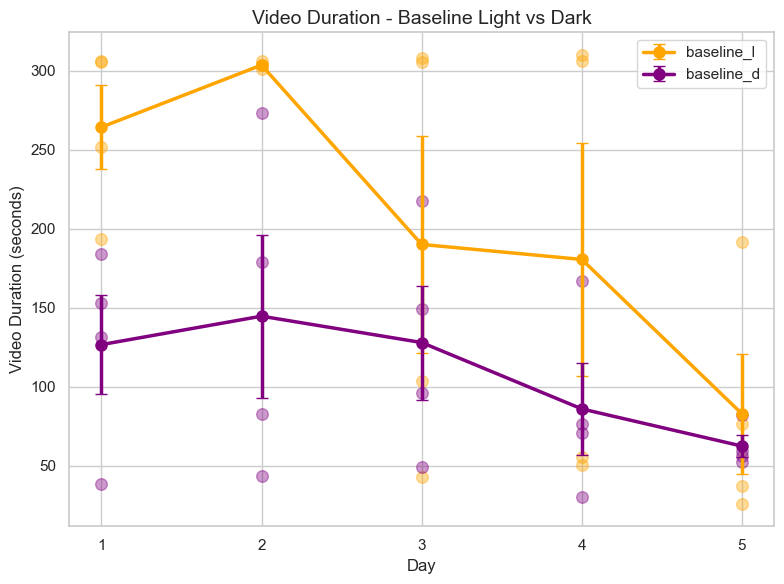

/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


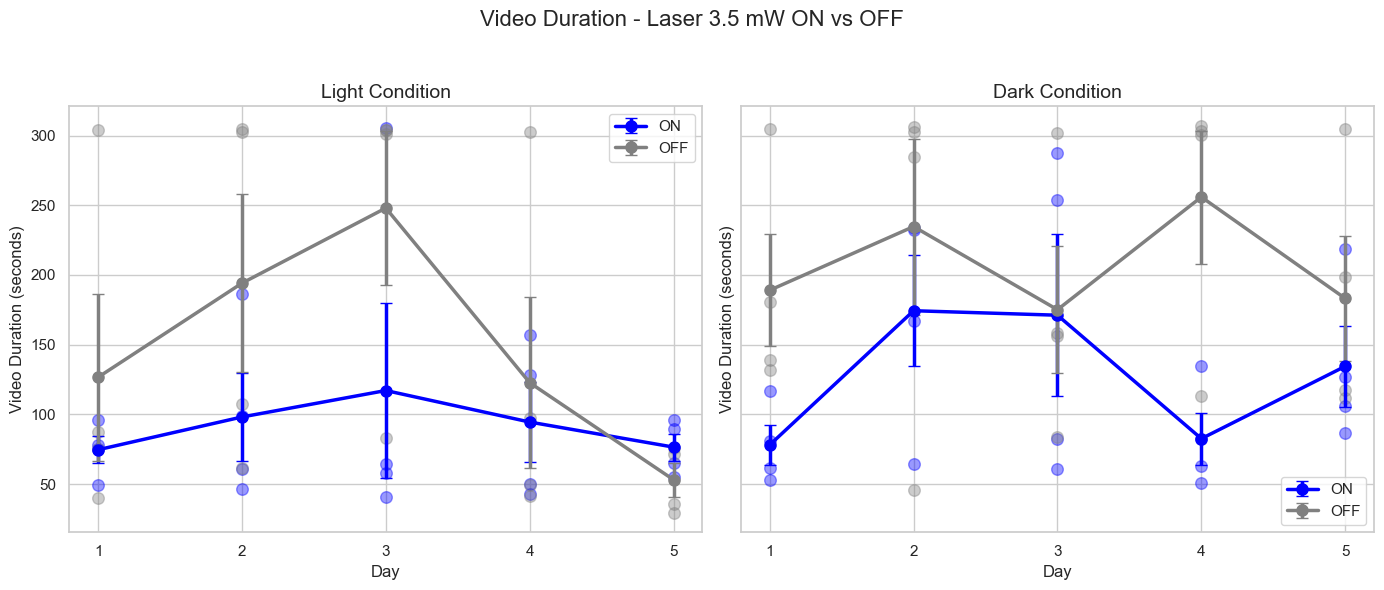

/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


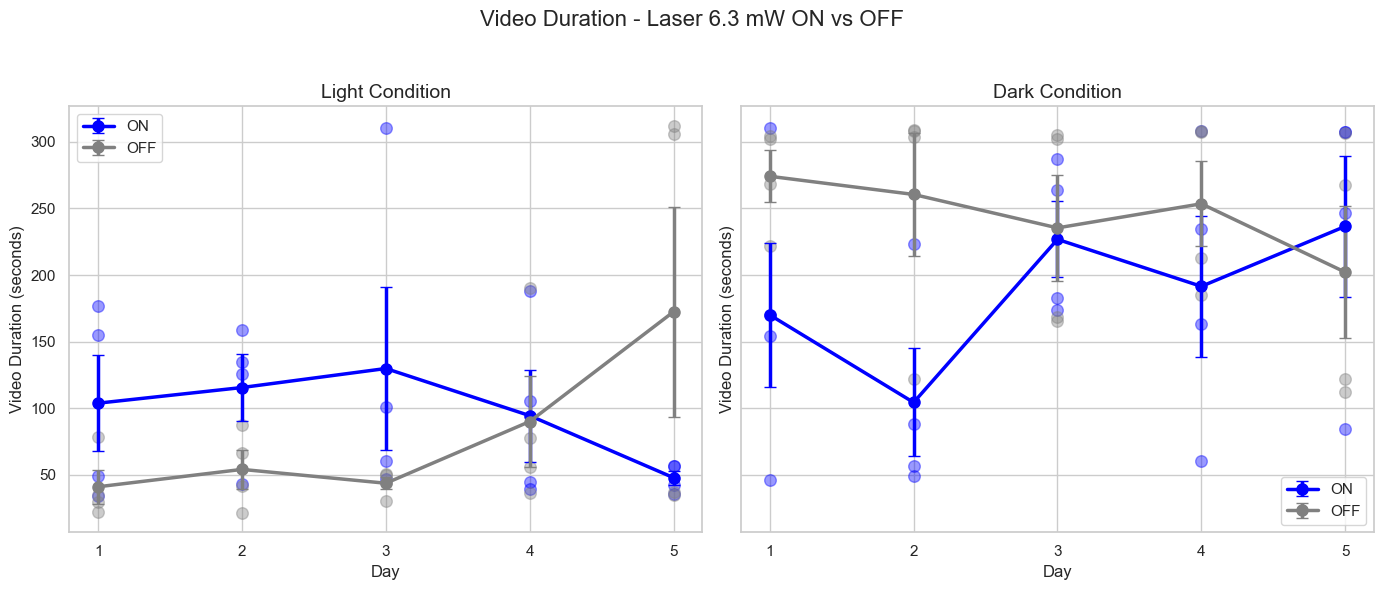

In [165]:
plot_duration_comparison(test_df, "Video Duration")



In [186]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.stats import sem
import pandas as pd

def plot_duration_and_removal_comparison(df_subset, title_base):
    # Calculate filtered out videos (Duration_sec >= 300)
    filtered_out = df_subset[df_subset['Duration_sec'] >= 290]

    # Total counts per ConditionCategory, Laser, and Day
    total_counts = (
        df_subset
        .groupby(['ConditionCategory', 'Laser', 'Day'])
        .size()
        .reset_index(name='TotalTrials')
    )

    # Counts of removed videos per ConditionCategory, Laser, and Day
    filtered_counts = (
        filtered_out
        .groupby(['ConditionCategory', 'Laser', 'Day'])
        .size()
        .reset_index(name='FilteredOutCount')
    )

    # Merge and calculate percentage removed
    perc_removed = pd.merge(total_counts, filtered_counts, how='left', on=['ConditionCategory', 'Laser', 'Day'])
    perc_removed['FilteredOutCount'] = perc_removed['FilteredOutCount'].fillna(0)
    perc_removed['PercentRemoved'] = (perc_removed['FilteredOutCount'] / perc_removed['TotalTrials']) * 100

    # Filter original df to exclude long videos
    df_subset = df_subset[df_subset['Duration_sec'] < 290]

    # Include baseline_l and baseline_d plus all rows where ConditionCategory contains 'pc' (case-insensitive)
    df_subset = df_subset[
        df_subset['ConditionCategory'].isin(['baseline_l', 'baseline_d']) |
        df_subset['ConditionCategory'].str.contains('pc', case=False, na=False)
    ]

    # Colors
    baseline_palette = {
        'baseline_l': 'orange',
        'baseline_d': 'purple'
    }
    laser_palette = {
        'ON': 'blue',
        'OFF': 'grey'
    }

    def plot_summary(ax, sub_df, group_col, palette_map, title):
        summary = (
            sub_df
            .groupby([group_col, 'Day', 'Mouse'])['Duration_sec']
            .median()
            .reset_index()
            .groupby([group_col, 'Day'])
            .agg(
                mean_duration=('Duration_sec', 'mean'),
                sem_duration=('Duration_sec', sem)
            )
            .reset_index()
        )

        mouse_medians = (
            sub_df
            .groupby([group_col, 'Mouse', 'Day'], as_index=False)['Duration_sec']
            .median()
        )

        for condition, color in palette_map.items():
            cond_summary = summary[summary[group_col] == condition]
            ax.errorbar(
                cond_summary['Day'],
                cond_summary['mean_duration'],
                yerr=cond_summary['sem_duration'],
                label=condition,
                color=color,
                lw=2.5,
                marker='o',
                capsize=4,
                markersize=8
            )
            subset = mouse_medians[mouse_medians[group_col] == condition]
            ax.scatter(subset['Day'], subset['Duration_sec'], color=color, alpha=0.4, s=70)

        ax.set_title(title, fontsize=14)
        ax.set_xlabel("Day")
        ax.set_ylabel("Video Duration (seconds)")
        ax.set_xticks(range(1, 6))
        ax.legend()

    # --- 1. Baseline plot ---
    baseline_df = df_subset[df_subset['ConditionCategory'].isin(['baseline_l', 'baseline_d'])]

    plt.figure(figsize=(10,7))
    ax = plt.gca()
    plot_summary(
        ax,
        baseline_df,
        group_col='ConditionCategory',
        palette_map=baseline_palette,
        title=f"{title_base} - Baseline Light vs Dark"
    )

    # Add percentage removed table as text inside baseline plot
    baseline_perc = perc_removed[perc_removed['ConditionCategory'].isin(['baseline_l', 'baseline_d'])]
    if not baseline_perc.empty:
        table_data = baseline_perc.pivot(index='Day', columns='ConditionCategory', values='PercentRemoved').fillna(0).round(1)
        table_str = table_data.to_string()
        ax.text(1.05, 0.5, table_str, fontsize=10, family='monospace',
                transform=ax.transAxes, verticalalignment='center', bbox=dict(facecolor='white', alpha=0.8))

    plt.tight_layout()
    plt.show()

    # --- 2. Duration plots for power 6.3 and 3.5 mW (laser ON/OFF in light and dark) ---
    power_levels = ['6.3', '3.5']

    for power in power_levels:
        power_df = df_subset[df_subset['ConditionCategory'].str.endswith(f"_{power}", na=False)]
        if power_df.empty:
            print(f"No data for power {power} mW")
            continue

        light_df = power_df[power_df['ConditionCategory'].str.contains('light', case=False, na=False)]
        dark_df = power_df[power_df['ConditionCategory'].str.contains('dark', case=False, na=False)]

        fig, axs = plt.subplots(1, 2, figsize=(14,6), sharey=True)
        fig.suptitle(f"{title_base} - Laser {power} mW ON vs OFF", fontsize=16)

        # Duration plot light
        if not light_df.empty:
            plot_summary(
                axs[0],
                light_df,
                group_col='Laser',
                palette_map=laser_palette,
                title='Light Condition'
            )
        else:
            axs[0].set_visible(False)

        # Duration plot dark
        if not dark_df.empty:
            plot_summary(
                axs[1],
                dark_df,
                group_col='Laser',
                palette_map=laser_palette,
                title='Dark Condition'
            )
        else:
            axs[1].set_visible(False)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

        # --- 3. Percent removed plots for this power (laser ON vs OFF, light/dark) ---
        power_perc = perc_removed[perc_removed['ConditionCategory'].str.endswith(f"_{power}", na=False)]
        if power_perc.empty:
            print(f"No percent removal data for power {power} mW")
            continue

        fig, axs = plt.subplots(1, 2, figsize=(14,6), sharey=True)
        fig.suptitle(f"{title_base} - Percent Videos Removed at {power} mW", fontsize=16)

        for i, condition_light_dark in enumerate(['light', 'dark']):
            conds = [c for c in power_perc['ConditionCategory'].unique() if condition_light_dark in c.lower()]
            ax = axs[i]
            for laser_state, color in laser_palette.items():
                # Filter for Laser state and light/dark condition
                subset = power_perc[
                    (power_perc['Laser'] == laser_state) &
                    (power_perc['ConditionCategory'].isin(conds))
                ]
                # Group by Day, average across conditions if multiple
                if subset.empty:
                    continue
                grouped = subset.groupby('Day')['PercentRemoved'].mean().reset_index()
                ax.plot(grouped['Day'], grouped['PercentRemoved'], marker='o', label=laser_state, color=color)

            ax.set_title(f"{condition_light_dark.capitalize()} Condition")
            ax.set_xlabel('Day')
            ax.set_ylabel('Percent Videos Removed (%)')
            ax.set_xticks(range(1, 6))
            ax.set_ylim(0, 100)
            ax.legend()
            ax.grid(True)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()


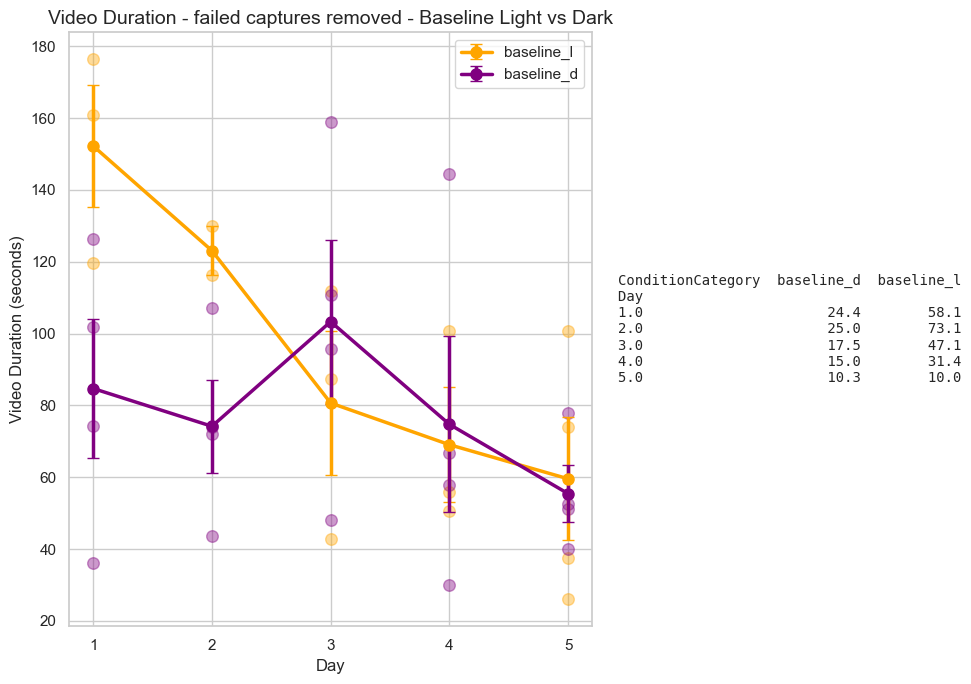

/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


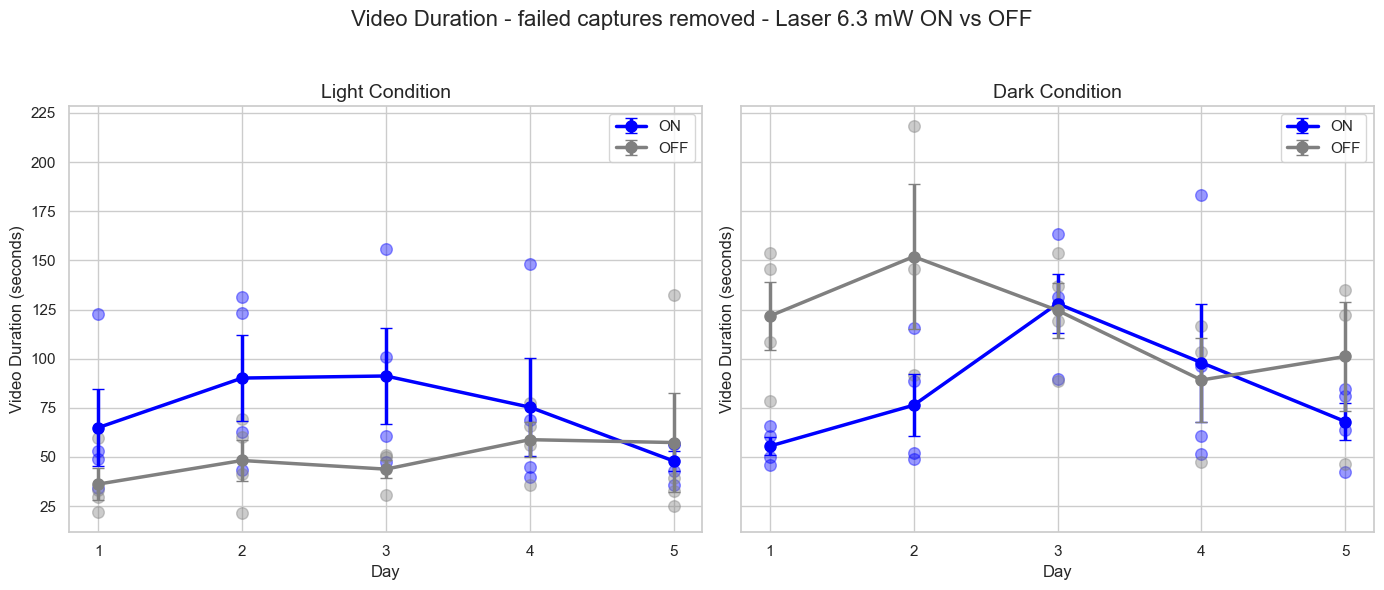

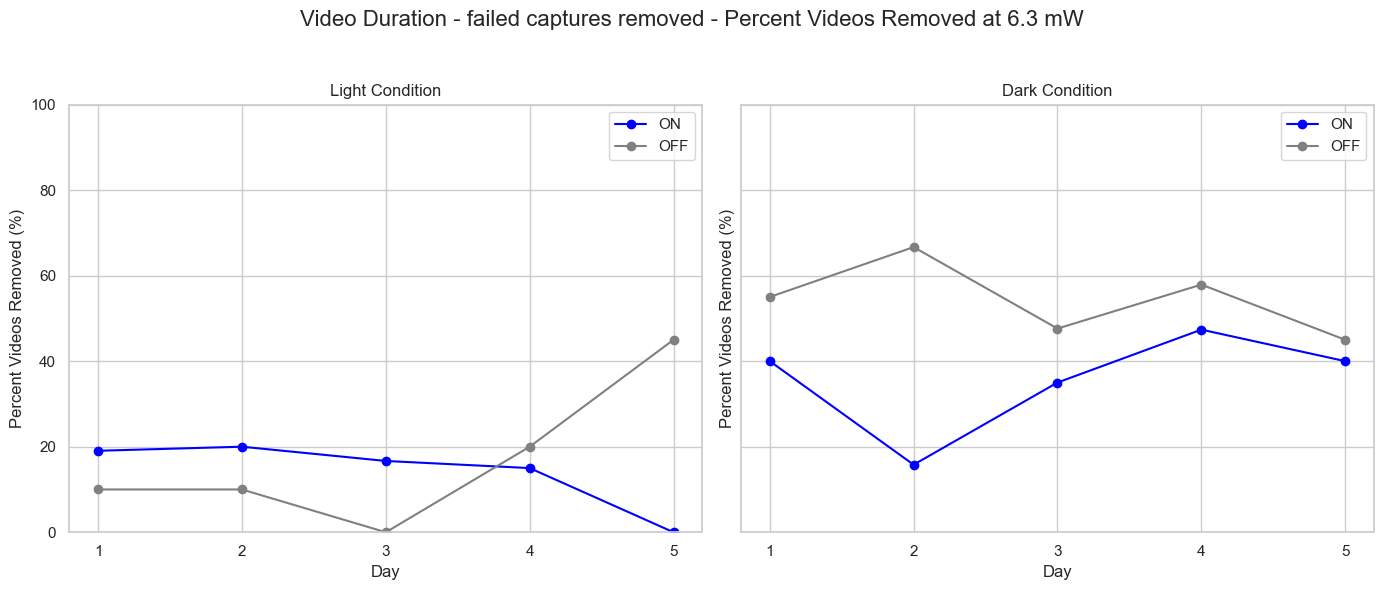

/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


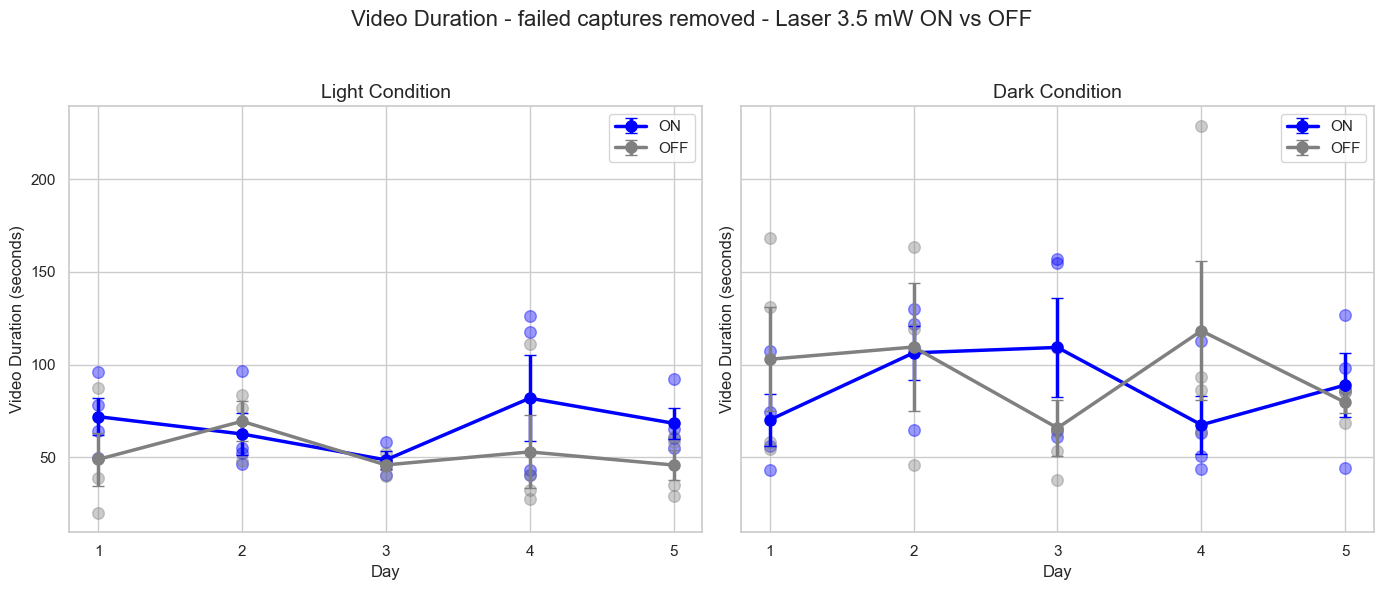

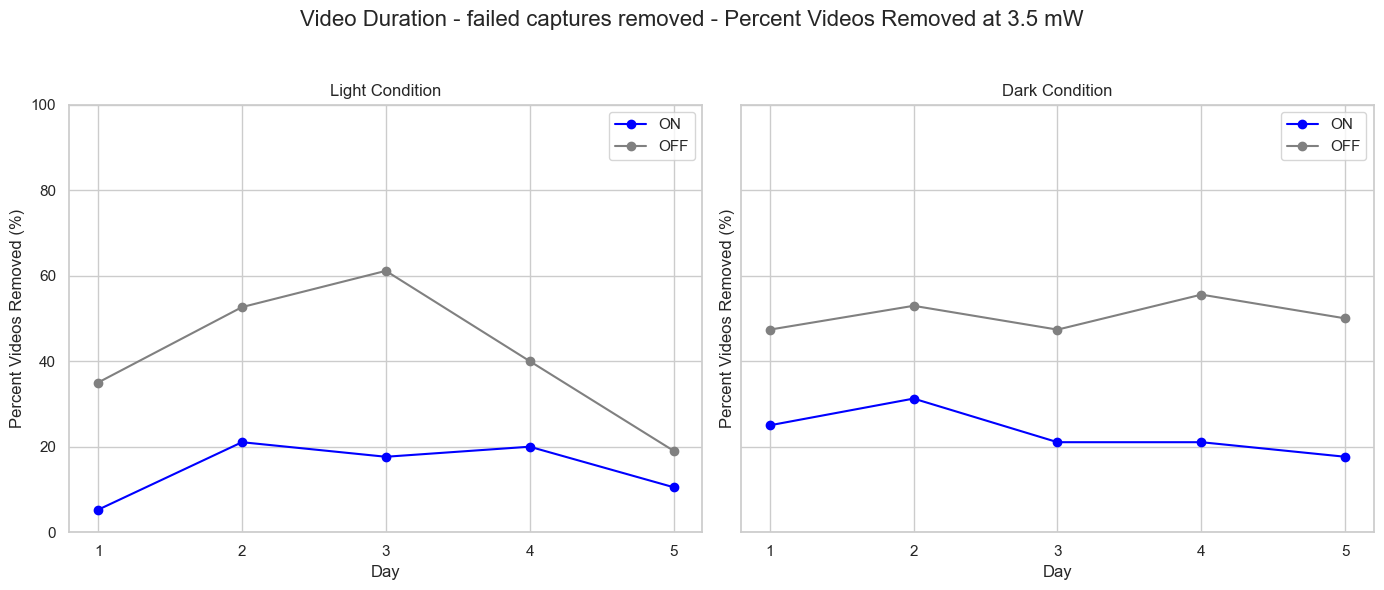

In [187]:
plot_duration_and_removal_comparison(test_df, "Video Duration - failed captures removed")


In [179]:
def add_sex_column(df):
    sex_map = {
        3352: 'F',
        3353: 'F',
        3355: 'M',
        3356: 'M'
    }
    df = df.copy()
    df['Sex'] = df['Mouse'].map(sex_map)
    return df

# Apply the function to your DataFrame
new_df = add_sex_column(test_df)

# Optional: check that it's correct
print(new_df[['Mouse', 'Sex']].drop_duplicates().sort_values(by='Mouse'))


      Mouse  Sex
0      3277  NaN
1      3352    F
345    3353    F
715    3355    M
1074   3356    M


In [191]:
if __name__ == "__main__":
    parent_directory = "/Volumes/Projects/PreyCapture/ZIActivation/Zhao_VgatChR2_protocol/"  # ← CHANGE THIS
    output_csv = "/Volumes/Projects/PreyCapture/ZIActivation/Zhao_VgatChR2_protocol/conditions_summary.csv"
    scan_subdirs_and_write_csv(parent_directory, output_csv)


✅ CSV written to: /Volumes/Projects/PreyCapture/ZIActivation/Zhao_VgatChR2_protocol/conditions_summary.csv (480 entries)


In [193]:
if __name__ == "__main__":
    existing_csv = "/Volumes/Projects/PreyCapture/ZIActivation/Zhao_VgatChR2_protocol/conditions_summary.csv"
    parent_directory = "/Volumes/Projects/PreyCapture/ZIActivation/Zhao_VgatChR2_protocol/"
    updated_csv = "/Volumes/Projects/PreyCapture/ZIActivation/Zhao_VgatChR2_protocol/conditions_summary_with_lengths.csv"

    update_csv_with_fixed_fps_video_lengths(existing_csv, parent_directory, updated_csv)

Scanning all directories under parent_dir once and building lookup dictionary...


Walking parent_dir: 6252it [03:38, 28.57it/s]


Found 980 unique folder names.

Processing 480 entries...


Folders processed:   0%|                                                       | 1/480 [00:00<06:44,  1.18folder/s]

Found video for 2025-06-09_10-45-22_mouse-3838: Sky_mouse-3838_2025-06-09T10_45_19.mp4 (Frames: 62813, Duration: 314.06s)


Folders processed:   0%|▏                                                      | 2/480 [00:01<04:47,  1.66folder/s]

... (945 outputs left out)

Folders processed: 100%|████████████████████████████████████████████████████▉| 479/480 [03:21<00:00,  2.26folder/s]

Found video for 2025-06-20_11-21-39_mouse-3841: Sky_mouse-3841_2025-06-20T11_21_35.mp4 (Frames: 62664, Duration: 313.32s)


Folders processed: 100%|█████████████████████████████████████████████████████| 480/480 [03:22<00:00,  2.38folder/s]

Found video for 2025-06-20_11-33-35_mouse-3841: Sky_mouse-3841_2025-06-20T11_33_31.mp4 (Frames: 24821, Duration: 124.11s)

✅ Updated CSV written to: /Volumes/Projects/PreyCapture/ZIActivation/Zhao_VgatChR2_protocol/conditions_summary_with_lengths.csv (480 entries)


In [195]:
# import pandas as pd
import re

# Load your CSV
csv_path = "/Volumes/Projects/PreyCapture/ZIActivation/Zhao_VgatChR2_protocol/conditions_summary_with_lengths.csv"
df = pd.read_csv(csv_path)

# Extract mouse number using regex (looks for 'mouse-1234' or 'mouse_1234')
df['Mouse'] = df['Folder'].str.extract(r'mouse[-_]?(\d+)', expand=False)

# Optional: convert to numeric
df['Mouse'] = pd.to_numeric(df['Mouse'], errors='coerce')

# Preview result
print(df[['Folder', 'Mouse']].head())

# Ensure 'Date' is datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Extract just the date (no time component) to group by day
df['DateOnly'] = df['Date'].dt.date

# Determine which dates are full baseline (Laser == 'OFF' for all rows that day)
baseline_dates = df.groupby('DateOnly')['Laser'].apply(lambda x: int(all(x == 'OFF')))

# Map the result back to each row
df['Baseline'] = df['DateOnly'].map(baseline_dates)

# Drop the helper column if you don't want it
df.drop(columns='DateOnly', inplace=True)

# Preview
print(df[['Date', 'Laser', 'Baseline']].head(10))


import pandas as pd

# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Normalize and simplify 'Condition'
df['Condition'] = df['Condition'].str.lower().str.strip()
df['ConditionCategory'] = df['Condition'].map({
    'pc | light': 'pc_light',
    'pc | dark': 'pc_dark'
})

# Initialize Day column
df['Day'] = None

# Define the groups of interest
group_conditions = [
    {'baseline': 1, 'condition': 'pc_light'},
    {'baseline': 1, 'condition': 'pc_dark'},
    {'baseline': 0, 'condition': 'pc_light'},
    {'baseline': 0, 'condition': 'pc_dark'},
]

# Assign Day numbers for all matching dates, per group
for cond in group_conditions:
    mask = (df['Baseline'] == cond['baseline']) & (df['ConditionCategory'] == cond['condition'])
    
    # Get all unique dates for this group, sorted
    unique_dates = sorted(df.loc[mask, 'Date'].dt.date.unique())
    
    # Create date → day number mapping
    date_to_day = {date: i + 1 for i, date in enumerate(unique_dates)}
    
    # Assign day number to matching rows
    df.loc[mask, 'Day'] = df.loc[mask, 'Date'].dt.date.map(date_to_day)

# Convert to integer
df['Day'] = pd.to_numeric(df['Day'], errors='coerce')

# Preview results
print(df[['Date', 'ConditionCategory', 'Baseline', 'Day']].dropna().sort_values(by=['ConditionCategory', 'Baseline', 'Day']).head(20))

# Define a function to modify ConditionCategory based on Baseline and Day
def modify_condition(row):
    if row['Baseline'] == 0 and 1 <= row['Day'] <= 5:
        return f"{row['ConditionCategory']}_6.3"
    elif row['Baseline'] == 0 and 6 <= row['Day'] <= 10:
        return f"{row['ConditionCategory']}_3.5"
    else:
        return row['ConditionCategory']

# Apply function row-wise
df['ConditionCategory'] = df.apply(modify_condition, axis=1)

# Copy DataFrame to avoid overwriting original, if needed
novice_df = df.copy()

# Baseline == 1
# Exclude rows with 'habituation' or 'exp' in Condition (case-insensitive)
baseline_mask = (
    (novice_df['Baseline'] == 1) &
    (~novice_df['Condition'].str.contains('habituation', case=False, na=False)) &
    (~novice_df['Condition'].str.contains('exp', case=False, na=False))
)

# Set baseline_l for conditions containing 'light'
novice_df.loc[
    baseline_mask & novice_df['Condition'].str.contains('light', case=False, na=False),
    'ConditionCategory'
] = 'baseline_l'

# Set baseline_d for conditions containing 'dark'
novice_df.loc[
    baseline_mask & novice_df['Condition'].str.contains('dark', case=False, na=False),
    'ConditionCategory'
] = 'baseline_d'

def reset_days_by_earliest_date(df):
    df = df.copy()
    df['Date'] = pd.to_datetime(df['Date'])

    def assign_days(sub_df):
        unique_dates = sorted(sub_df['Date'].unique())
        date_to_day = {date: day+1 for day, date in enumerate(unique_dates)}
        # Create a new Day column for the subset
        return sub_df.assign(Day=sub_df['Date'].map(date_to_day))

    # Use transform to preserve all rows and just replace the Day column
    df['Day'] = (
        df.groupby('ConditionCategory', dropna=True)
          .apply(assign_days)
          .sort_index()['Day']
    )
    return df

novice_df = reset_days_by_earliest_date(novice_df)

                           Folder  Mouse
0  2025-06-09_10-45-22_mouse-3838   3838
1  2025-06-09_10-50-48_mouse-3838   3838
2  2025-06-09_11-12-20_mouse-3838   3838
3  2025-06-09_11-00-54_mouse-3838   3838
4  2025-06-09_11-06-28_mouse-3838   3838
        Date Laser  Baseline
0 2025-06-09   OFF         0
1 2025-06-09   OFF         0
2 2025-06-09    ON         0
3 2025-06-09    ON         0
4 2025-06-09    ON         0
5 2025-06-09    ON         0
6 2025-06-09    ON         0
7 2025-06-09   OFF         0
8 2025-06-09   OFF         0
9 2025-06-09   OFF         0
          Date ConditionCategory  Baseline  Day
60  2025-06-16           pc_dark         0  1.0
63  2025-06-16           pc_dark         0  1.0
64  2025-06-16           pc_dark         0  1.0
65  2025-06-16           pc_dark         0  1.0
66  2025-06-16           pc_dark         0  1.0
67  2025-06-16           pc_dark         0  1.0
68  2025-06-16           pc_dark         0  1.0
69  2025-06-16           pc_dark         0  1.0
70 

/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_64407/2625785559.py:125: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)
  df.groupby('ConditionCategory', dropna=True)


In [196]:
novice_df

,Folder,Mouse,Date,Condition,Laser,Frames,Duration_sec,Baseline,ConditionCategory,Day
0,2025-06-09_10-45-22_mouse-3838,3838,2025-06-09,exp | light,OFF,62813,314.06,0,NaN,NaN
1,2025-06-09_10-50-48_mouse-3838,3838,2025-06-09,exp | dark,OFF,62862,314.31,0,NaN,NaN
2,2025-06-09_11-12-20_mouse-3838,3838,2025-06-09,pc | light,ON,23535,117.67,0,pc_light_6.3,1.0
3,2025-06-09_11-00-54_mouse-3838,3838,2025-06-09,pc | light,ON,6162,30.81,0,pc_light_6.3,1.0
4,2025-06-09_11-06-28_mouse-3838,3838,2025-06-09,pc | light,ON,22538,112.69,0,pc_light_6.3,1.0
...,...,...,...,...,...,...,...,...,...,...
475,2025-06-20_11-36-53_mouse-3841,3841,2025-06-20,pc | dark,OFF,61384,306.92,0,pc_dark_6.3,5.0
476,2025-06-20_11-59-13_mouse-3841,3841,2025-06-20,pc | dark,ON,8184,40.92,0,pc_dark_6.3,5.0
477,2025-06-20_11-27-01_mouse-3841,3841,2025-06-20,exp | dark,OFF,61226,306.13,0,NaN,NaN
478,2025-06-20_11-21-39_mouse-3841,3841,2025-06-20,exp | light,OFF,62664,313.32,0,NaN,NaN


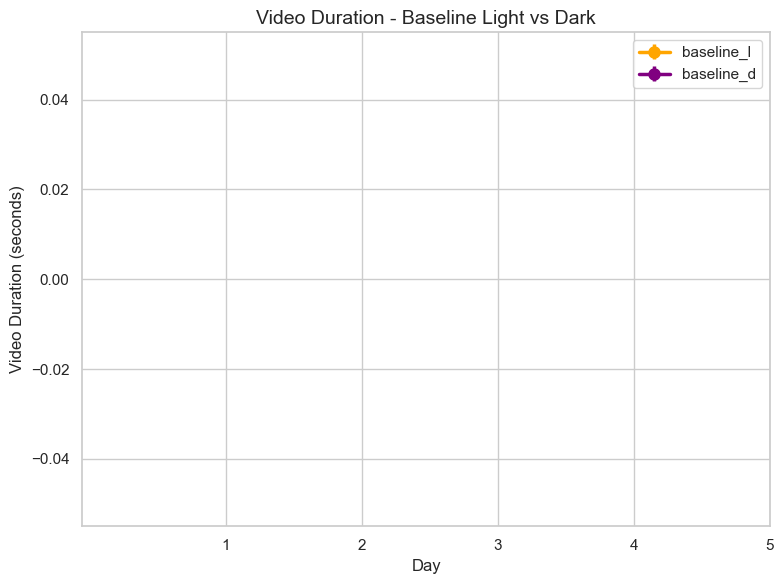

No data for power 3.5 mW


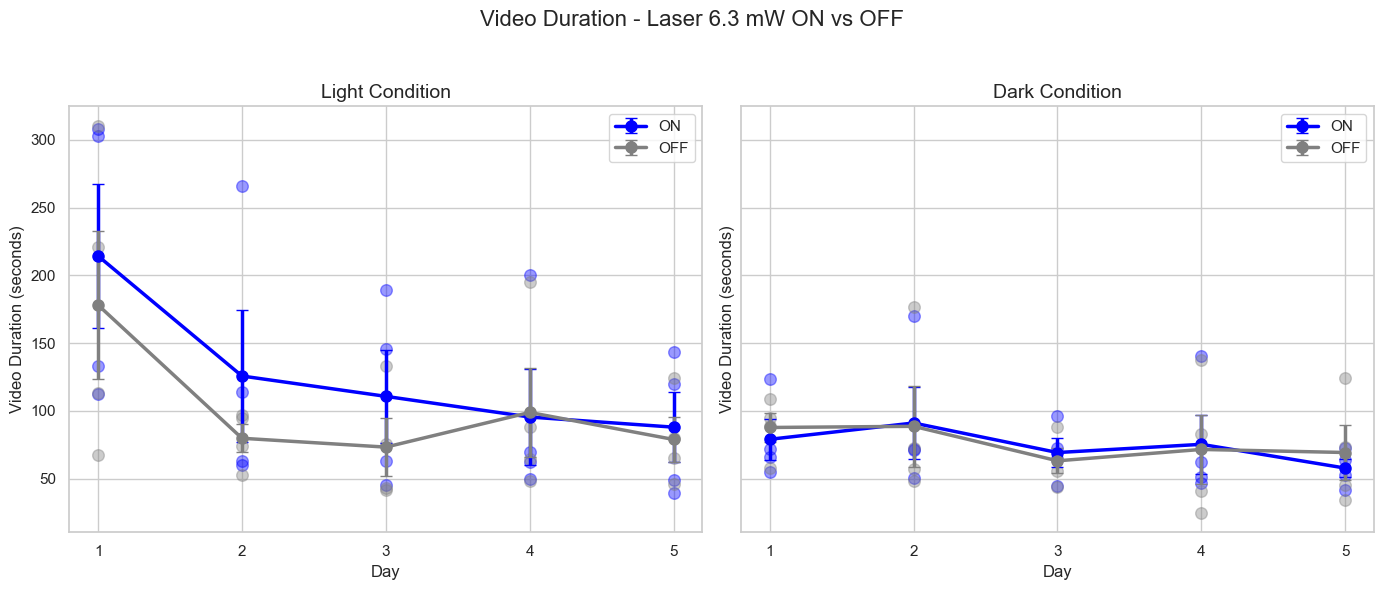

In [197]:
plot_duration_comparison(novice_df, "Video Duration")

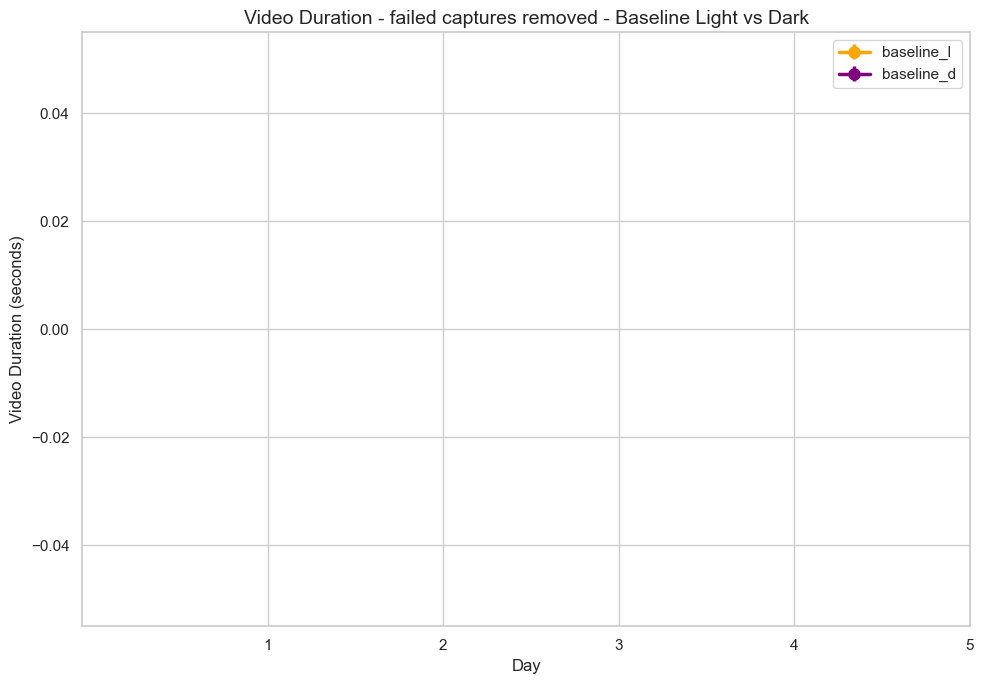

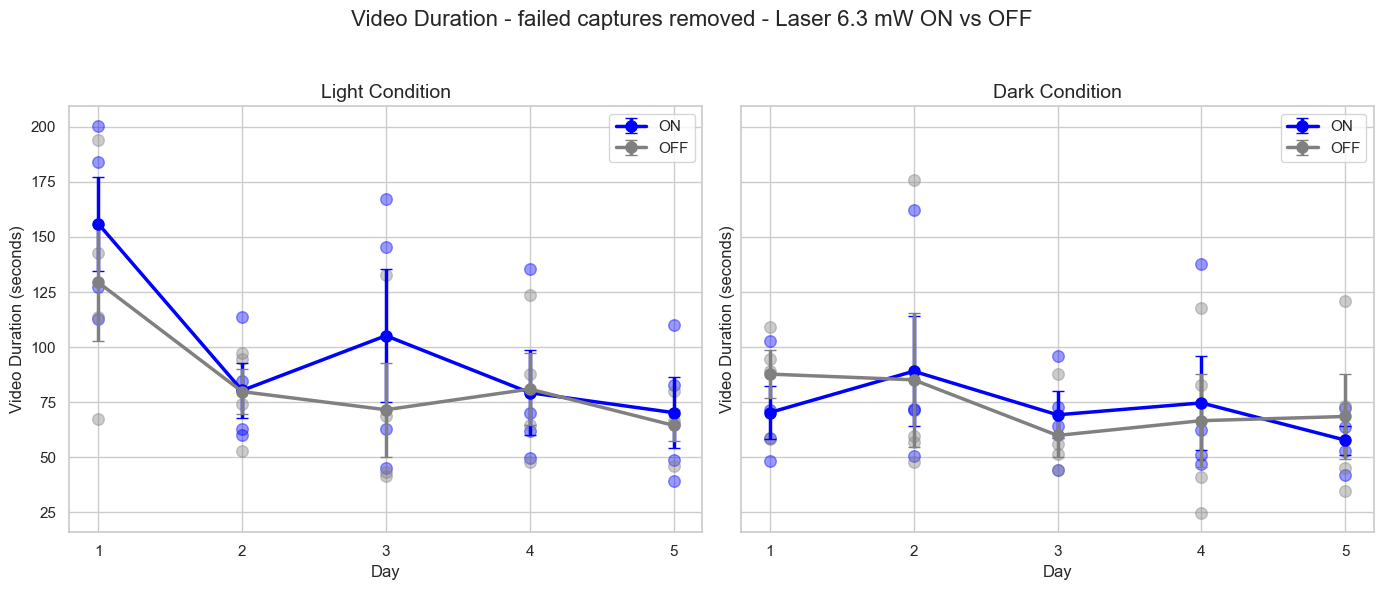

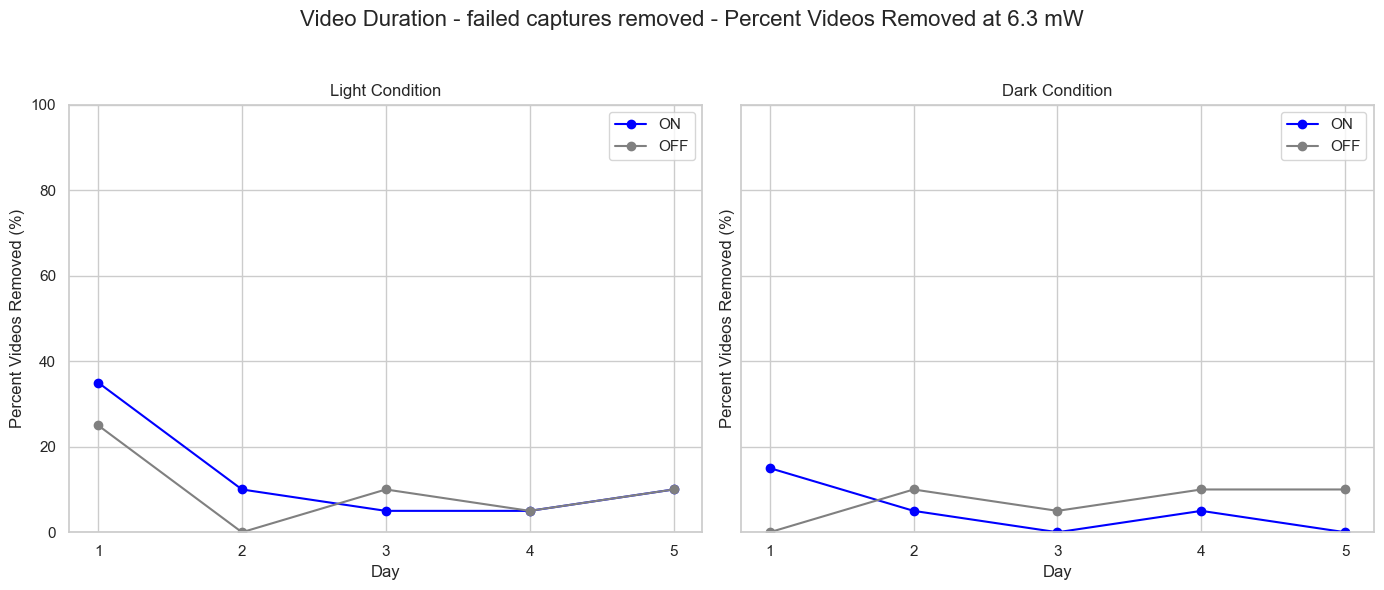

No data for power 3.5 mW


In [198]:
plot_duration_and_removal_comparison(novice_df, "Video Duration - failed captures removed")

In [200]:
if __name__ == "__main__":
    parent_directory = "/Volumes/Projects/PreyCapture/ZI_A1Activation/"  # ← CHANGE THIS
    output_csv = "/Volumes/Projects/PreyCapture/ZI_A1Activation/conditions_summary.csv"
    scan_subdirs_and_write_csv(parent_directory, output_csv)

[!] Error reading stimlog.json: /Volumes/Projects/PreyCapture/ZI_A1Activation/2025-02-27_9-30-09_mouse-3179/2025-02-27_09-30-10_mouse-3179/stimlog.json: 'str' object has no attribute 'get'
[!] Error reading stimlog.json: /Volumes/Projects/PreyCapture/ZI_A1Activation/2025-02-27_9-51-40_mouse-3179/2025-02-27_09-51-42_mouse-3179/stimlog.json: 'str' object has no attribute 'get'
[!] Error reading stimlog.json: /Volumes/Projects/PreyCapture/ZI_A1Activation/2025-03-06_11-04-49_mouse-3181/2025-03-06_11-04-51_mouse-3181/stimlog.json: 'str' object has no attribute 'get'
[!] Error reading stimlog.json: /Volumes/Projects/PreyCapture/ZI_A1Activation/2025-02-06_8-54-40_mouse-3179/2025-02-06_08-54-43_mouse-3179/stimlog.json: 'str' object has no attribute 'get'
[!] Error reading stimlog.json: /Volumes/Projects/PreyCapture/ZI_A1Activation/2025-01-28_8-44-52_mouse-3179/2025-01-28_08-44-56_mouse-3179/stimlog.json: 'str' object has no attribute 'get'
[!] Error reading stimlog.json: /Volumes/Projects/Prey

In [201]:
if __name__ == "__main__":
    existing_csv = "/Volumes/Projects/PreyCapture/ZI_A1Activation/conditions_summary.csv"
    parent_directory = "/Volumes/Projects/PreyCapture/ZI_A1Activation/"
    updated_csv = "/Volumes/Projects/PreyCapture/ZI_A1Activation/conditions_summary_with_lengths.csv"

    update_csv_with_fixed_fps_video_lengths(existing_csv, parent_directory, updated_csv)

Scanning all directories under parent_dir once and building lookup dictionary...


Walking parent_dir: 95228it [1:06:37, 23.82it/s]


Found 35416 unique folder names.

Processing 2772 entries...


Folders processed:   0%|                                                      | 1/2772 [00:00<36:36,  1.26folder/s]

Found video for 2025-01-13_09-02-30_mouse-3179: Sky_mouse-3179_2025-01-13T09_02_26.mp4 (Frames: 122536, Duration: 612.68s)


Folders processed:   0%|                                                      | 2/2772 [00:01<28:41,  1.61folder/s]

... (4,962 outputs left out)

Folders processed: 100%|██████████████████████████████████████████████████▉| 2771/2772 [13:44<00:00,  3.29folder/s]

Found video for 2025-08-13_10-08-43_mouse-3674: Sky_mouse-3674_2025-08-13T10_08_39.mp4 (Frames: 63105, Duration: 315.52s)


Folders processed: 100%|███████████████████████████████████████████████████| 2772/2772 [13:45<00:00,  3.36folder/s]

Found video for 2025-01-27_09-18-40_mouse-unknown: Sky_mouse-3179_2025-01-27T09_18_36.mp4 (Frames: 64506, Duration: 322.53s)

✅ Updated CSV written to: /Volumes/Projects/PreyCapture/ZI_A1Activation/conditions_summary_with_lengths.csv (2772 entries)


In [213]:


# import pandas as pd
import re

# Load your CSV
csv_path = "/Volumes/Projects/PreyCapture/ZI_A1Activation/conditions_summary_with_lengths.csv"
df = pd.read_csv(csv_path)

# Extract mouse number using regex (looks for 'mouse-1234' or 'mouse_1234')
df['Mouse'] = df['Folder'].str.extract(r'mouse[-_]?(\d+)', expand=False)

# Optional: convert to numeric
df['Mouse'] = pd.to_numeric(df['Mouse'], errors='coerce')

# Preview result
print(df[['Folder', 'Mouse']].head())

# Ensure 'Date' is datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Extract just the date (no time component) to group by day
df['DateOnly'] = df['Date'].dt.date

# Determine which dates are full baseline (Laser == 'OFF' for all rows that day)
baseline_dates = df.groupby('DateOnly')['Laser'].apply(lambda x: int(all(x == 'OFF')))

# Map the result back to each row
df['Baseline'] = df['DateOnly'].map(baseline_dates)

# Drop the helper column if you don't want it
df.drop(columns='DateOnly', inplace=True)

# Preview
print(df[['Date', 'Laser', 'Baseline']].head(10))


# import pandas as pd

# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Normalize and simplify 'Condition'
df['Condition'] = df['Condition'].str.lower().str.strip()
df['ConditionCategory'] = df['Condition'].map({
    'pc | light': 'pc_light',
    'pc | dark': 'pc_dark'
})

# Initialize Day column
df['Day'] = None

# Define the groups of interest
group_conditions = [
    {'baseline': 1, 'condition': 'pc_light'},
    {'baseline': 1, 'condition': 'pc_dark'},
    {'baseline': 0, 'condition': 'pc_light'},
    {'baseline': 0, 'condition': 'pc_dark'},
]

# Assign Day numbers for all matching dates, per group
for cond in group_conditions:
    mask = (df['Baseline'] == cond['baseline']) & (df['ConditionCategory'] == cond['condition'])
    
    # Get all unique dates for this group, sorted
    unique_dates = sorted(df.loc[mask, 'Date'].dt.date.unique())
    
    # Create date → day number mapping
    date_to_day = {date: i + 1 for i, date in enumerate(unique_dates)}
    
    # Assign day number to matching rows
    df.loc[mask, 'Day'] = df.loc[mask, 'Date'].dt.date.map(date_to_day)

# Convert to integer
df['Day'] = pd.to_numeric(df['Day'], errors='coerce')

# Preview results
print(df[['Date', 'ConditionCategory', 'Baseline', 'Day']].dropna().sort_values(by=['ConditionCategory', 'Baseline', 'Day']).head(20))

# Define a function to modify ConditionCategory based on Baseline and Day
def modify_condition(row):
    if row['Baseline'] == 0 and 1 <= row['Day'] <= 5:
        return f"{row['ConditionCategory']}_6.3"
    elif row['Baseline'] == 0 and 6 <= row['Day'] <= 10:
        return f"{row['ConditionCategory']}_6.3"
    else:
        return row['ConditionCategory']

# Apply function row-wise
df['ConditionCategory'] = df.apply(modify_condition, axis=1)

# Copy DataFrame to avoid overwriting original, if needed
novice_df = df.copy()

# Baseline == 1
# Exclude rows with 'habituation' or 'exp' in Condition (case-insensitive)
baseline_mask = (
    (novice_df['Baseline'] == 1) &
    (~novice_df['Condition'].str.contains('habituation*', case=False, na=False)) &
    (~novice_df['Condition'].str.contains('exp*', case=False, na=False))
)

# Set baseline_l for conditions containing 'light'
novice_df.loc[
    baseline_mask & novice_df['Condition'].str.contains('light', case=False, na=False),
    'ConditionCategory'
] = 'baseline_l'

# Set baseline_d for conditions containing 'dark'
novice_df.loc[
    baseline_mask & novice_df['Condition'].str.contains('dark', case=False, na=False),
    'ConditionCategory'
] = 'baseline_d'

def reset_days_by_earliest_date(df):
    df = df.copy()
    df['Date'] = pd.to_datetime(df['Date'])

    def assign_days(sub_df):
        unique_dates = sorted(sub_df['Date'].unique())
        date_to_day = {date: day+1 for day, date in enumerate(unique_dates)}
        # Create a new Day column for the subset
        return sub_df.assign(Day=sub_df['Date'].map(date_to_day))

    # Use transform to preserve all rows and just replace the Day column
    df['Day'] = (
        df.groupby('ConditionCategory', dropna=True)
          .apply(assign_days)
          .sort_index()['Day']
    )
    return df

gad2_df = reset_days_by_earliest_date(novice_df)

                           Folder   Mouse
0  2025-01-13_09-02-30_mouse-3179  3179.0
1  2025-01-13_09-14-50_mouse-3179  3179.0
2  2025-01-14_08-48-23_mouse-3179  3179.0
3  2025-01-14_08-37-14_mouse-3179  3179.0
4  2025-01-15_09-37-13_mouse-3179  3179.0
        Date Laser  Baseline
0 2025-01-13   OFF         1
1 2025-01-13   OFF         1
2 2025-01-14   OFF         1
3 2025-01-14   OFF         1
4 2025-01-15   OFF         1
5 2025-01-15   OFF         1
6 2025-01-16   OFF         1
7 2025-01-16   OFF         1
8 2025-01-17   OFF         1
9 2025-01-17   OFF         1
          Date ConditionCategory  Baseline  Day
140 2025-02-03           pc_dark         0  1.0
141 2025-02-03           pc_dark         0  1.0
143 2025-02-03           pc_dark         0  1.0
144 2025-02-03           pc_dark         0  1.0
145 2025-02-03           pc_dark         0  1.0
146 2025-02-03           pc_dark         0  1.0
147 2025-02-03           pc_dark         0  1.0
148 2025-02-03           pc_dark         0  1

/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_64407/2799389487.py:125: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)
  df.groupby('ConditionCategory', dropna=True)


array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,
       14., 15., nan])

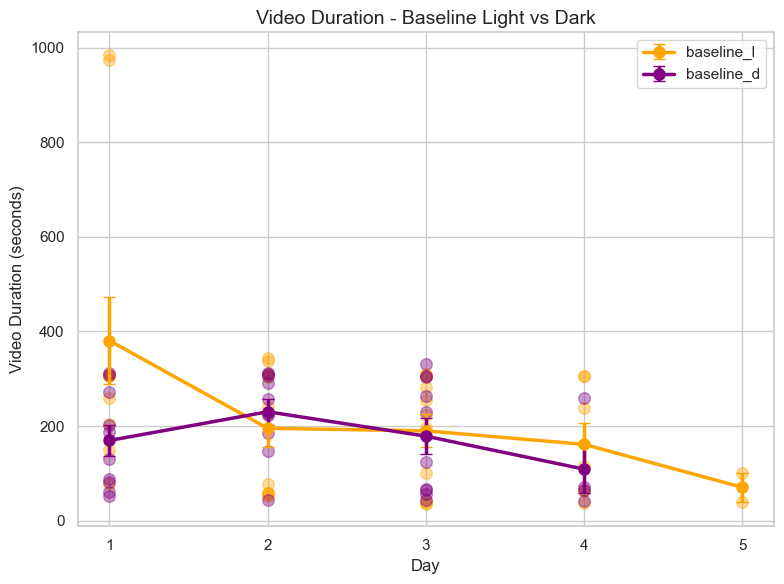

No data for power 3.5 mW


/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


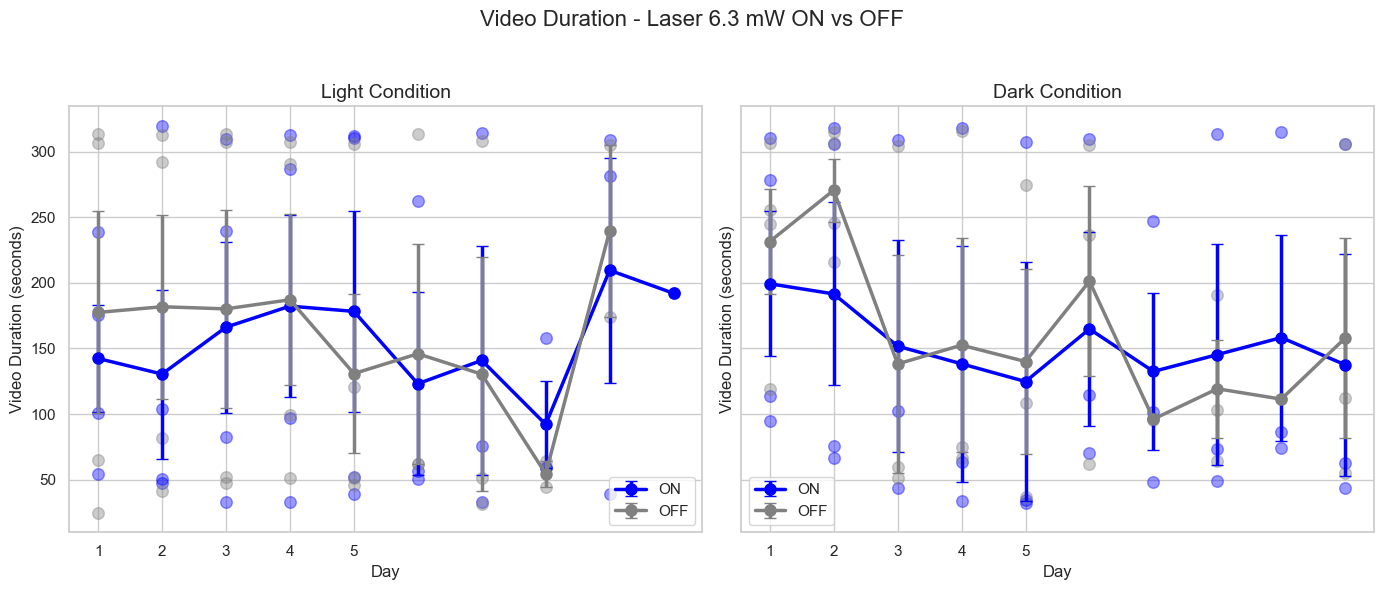

In [222]:
plot_duration_comparison(gad2_df, "Video Duration")

In [220]:
# Ensure Date column is datetime
gad2_df['Date'] = pd.to_datetime(gad2_df['Date'])

# Create a new 'Day' column initialized with NaNs
gad2_df['Day'] = pd.NA

# Group by MouseID, Baseline, and ConditionCategory
grouped = gad2_df.groupby(['Mouse', 'Baseline', 'ConditionCategory'])

# Assign day numbers per group
for (mouse, baseline, condition), group_df in grouped:
    # Sort by date and get unique dates
    unique_dates = sorted(group_df['Date'].dt.date.unique())
    
    # Map each date to a day number (starting from 1)
    date_to_day = {date: i + 1 for i, date in enumerate(unique_dates)}
    
    # Boolean mask to assign only to matching rows
    mask = (
        (gad2_df['Mouse'] == mouse) &
        (gad2_df['Baseline'] == baseline) &
        (gad2_df['ConditionCategory'] == condition)
    )
    
    gad2_df.loc[mask, 'Day'] = gad2_df.loc[mask, 'Date'].dt.date.map(date_to_day)

# Convert to integer
gad2_df['Day'] = pd.to_numeric(gad2_df['Day'], errors='coerce')


In [221]:
print(
    gad2_df[['Mouse', 'Date', 'ConditionCategory', 'Baseline', 'Day']]
    .dropna()
    .sort_values(by=['Mouse', 'ConditionCategory', 'Baseline', 'Day'])
    .head(20)
)


     Mouse       Date ConditionCategory  Baseline  Day
36  3179.0 2025-01-23        baseline_d         1  1.0
37  3179.0 2025-01-23        baseline_d         1  1.0
38  3179.0 2025-01-23        baseline_d         1  1.0
39  3179.0 2025-01-23        baseline_d         1  1.0
40  3179.0 2025-01-23        baseline_d         1  1.0
41  3179.0 2025-01-23        baseline_d         1  1.0
42  3179.0 2025-01-23        baseline_d         1  1.0
43  3179.0 2025-01-23        baseline_d         1  1.0
44  3179.0 2025-01-23        baseline_d         1  1.0
45  3179.0 2025-01-23        baseline_d         1  1.0
46  3179.0 2025-01-24        baseline_d         1  2.0
47  3179.0 2025-01-24        baseline_d         1  2.0
48  3179.0 2025-01-24        baseline_d         1  2.0
49  3179.0 2025-01-24        baseline_d         1  2.0
50  3179.0 2025-01-24        baseline_d         1  2.0
51  3179.0 2025-01-24        baseline_d         1  2.0
54  3179.0 2025-01-24        baseline_d         1  2.0
55  3179.0

In [224]:
# Ensure 'Day' is numeric
gad2_df['Day'] = pd.to_numeric(gad2_df['Day'], errors='coerce')

# Find rows where Day > 5
day_gt_5 = gad2_df[gad2_df['Day'] > 5]

# Show the results
print(day_gt_5[['Mouse', 'Date', 'ConditionCategory', 'Baseline', 'Day']])


       Mouse       Date ConditionCategory  Baseline   Day
127   3179.0 2025-02-01      pc_light_6.3         0   6.0
129   3179.0 2025-02-01      pc_light_6.3         0   6.0
130   3179.0 2025-02-01      pc_light_6.3         0   6.0
131   3179.0 2025-02-01      pc_light_6.3         0   6.0
132   3179.0 2025-02-01      pc_light_6.3         0   6.0
...      ...        ...               ...       ...   ...
2447  3278.0 2025-06-07          pc_light         0  10.0
2448  3278.0 2025-06-07          pc_light         0  10.0
2449  3278.0 2025-06-07          pc_light         0  10.0
2450  3278.0 2025-06-07          pc_light         0  10.0
2451  3278.0 2025-06-07          pc_light         0  10.0

[559 rows x 5 columns]


In [ ]:
np.unique(day_gt_5['Mouse'])

array([3179., 3181., 3182., 3275., 3276., 3277., 3278.])

In [231]:
# Ensure correct types
gad2_df['Date'] = pd.to_datetime(gad2_df['Date'])
gad2_df['Day'] = pd.to_numeric(gad2_df['Day'], errors='coerce')

# List of affected mice (replace with actual Mouse IDs)
affected_mice = [3275, 3276, 3277, 3278]  # ← update this

# Number of days to drop per condition
drop_days_map = {
    'pc_light': 5,
    'pc_dark': 3
}

# Prepare a list to collect cleaned data chunks
cleaned_chunks = []

# Group by Mouse, Baseline, and ConditionCategory
grouped = gad2_df.groupby(['Mouse', 'Baseline', 'ConditionCategory'])

for (mouse, baseline, condition), group_df in grouped:
    group_df = group_df.sort_values(by='Date').copy()
    
    # Check if this mouse and condition need trimming
    if mouse in affected_mice and condition in drop_days_map:
        # Drop first N rows by date
        group_df = group_df.iloc[drop_days_map[condition]:]
    
    # Recalculate Day numbers based on unique sorted dates
    unique_dates = sorted(group_df['Date'].dt.date.unique())
    date_to_day = {date: i + 1 for i, date in enumerate(unique_dates)}
    group_df['Day'] = group_df['Date'].dt.date.map(date_to_day)
    
    # Collect the cleaned group
    cleaned_chunks.append(group_df)

# Concatenate all cleaned groups into one DataFrame
gad2_df_cleaned = pd.concat(cleaned_chunks).reset_index(drop=True)

# Preview
print(
    gad2_df_cleaned[['Mouse', 'Date', 'ConditionCategory', 'Baseline', 'Day']]
    .sort_values(by=['Mouse', 'ConditionCategory', 'Date'])
    .head(20)
)


      Mouse       Date ConditionCategory  Baseline  Day
209  3179.0 2025-01-23        baseline_d         1    1
210  3179.0 2025-01-23        baseline_d         1    1
211  3179.0 2025-01-23        baseline_d         1    1
212  3179.0 2025-01-23        baseline_d         1    1
213  3179.0 2025-01-23        baseline_d         1    1
214  3179.0 2025-01-23        baseline_d         1    1
215  3179.0 2025-01-23        baseline_d         1    1
216  3179.0 2025-01-23        baseline_d         1    1
217  3179.0 2025-01-23        baseline_d         1    1
218  3179.0 2025-01-23        baseline_d         1    1
219  3179.0 2025-01-24        baseline_d         1    2
220  3179.0 2025-01-24        baseline_d         1    2
221  3179.0 2025-01-24        baseline_d         1    2
222  3179.0 2025-01-24        baseline_d         1    2
223  3179.0 2025-01-24        baseline_d         1    2
224  3179.0 2025-01-24        baseline_d         1    2
225  3179.0 2025-01-24        baseline_d        

In [233]:
gad2_df_cleaned

,Folder,Mouse,Date,Condition,Laser,Frames,Duration_sec,Baseline,ConditionCategory,Day
0,2025-02-03_10-45-04_mouse-3179,3179.0,2025-02-03,pc | dark,OFF,60819.0,304.10,0,pc_dark_6.3,1
1,2025-02-03_11-15-38_mouse-3179,3179.0,2025-02-03,pc | dark,OFF,61679.0,308.39,0,pc_dark_6.3,1
2,2025-02-03_11-09-01_mouse-3179,3179.0,2025-02-03,pc | dark,ON,61281.0,306.40,0,pc_dark_6.3,1
3,2025-02-03_10-56-41_mouse-3179,3179.0,2025-02-03,pc | dark,ON,62996.0,314.98,0,pc_dark_6.3,1
4,2025-02-03_10-28-49_mouse-3179,3179.0,2025-02-03,pc | dark,OFF,61323.0,306.62,0,pc_dark_6.3,1
...,...,...,...,...,...,...,...,...,...,...
2004,2025-08-03_12-53-57_mouse-3674,3674.0,2025-08-03,pc | light,OFF,37173.0,185.87,1,baseline_l,4
2005,2025-08-03_12-50-41_mouse-3674,3674.0,2025-08-03,pc | light,OFF,20918.0,104.59,1,baseline_l,4
2006,2025-08-03_12-59-03_mouse-3674,3674.0,2025-08-03,pc | light,OFF,61456.0,307.28,1,baseline_l,4
2007,2025-08-03_12-17-44_mouse-3674,3674.0,2025-08-03,pc | light,OFF,33976.0,169.88,1,baseline_l,4


In [230]:
# Ensure 'Day' is numeric
gad2_df['Day'] = pd.to_numeric(gad2_df['Day'], errors='coerce')

# Find rows where Day > 5
day_gt_5 = gad2_df[gad2_df['Day'] > 5]

# Show the results
print(day_gt_5[['Mouse', 'Date', 'ConditionCategory', 'Baseline', 'Day']])

       Mouse       Date ConditionCategory  Baseline   Day
127   3179.0 2025-02-01      pc_light_6.3         0   6.0
129   3179.0 2025-02-01      pc_light_6.3         0   6.0
130   3179.0 2025-02-01      pc_light_6.3         0   6.0
131   3179.0 2025-02-01      pc_light_6.3         0   6.0
132   3179.0 2025-02-01      pc_light_6.3         0   6.0
...      ...        ...               ...       ...   ...
2447  3278.0 2025-06-07          pc_light         0  10.0
2448  3278.0 2025-06-07          pc_light         0  10.0
2449  3278.0 2025-06-07          pc_light         0  10.0
2450  3278.0 2025-06-07          pc_light         0  10.0
2451  3278.0 2025-06-07          pc_light         0  10.0

[559 rows x 5 columns]


### separate out males and females, totally different behavior

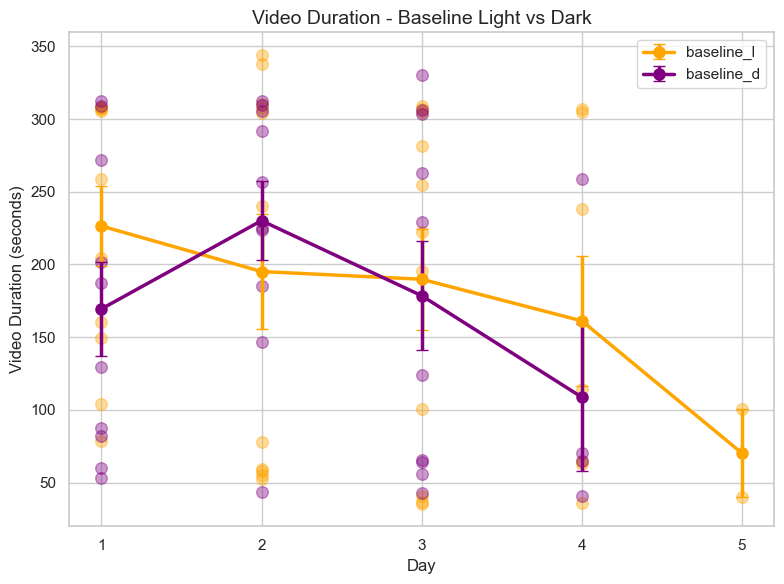

No data for power 3.5 mW


/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


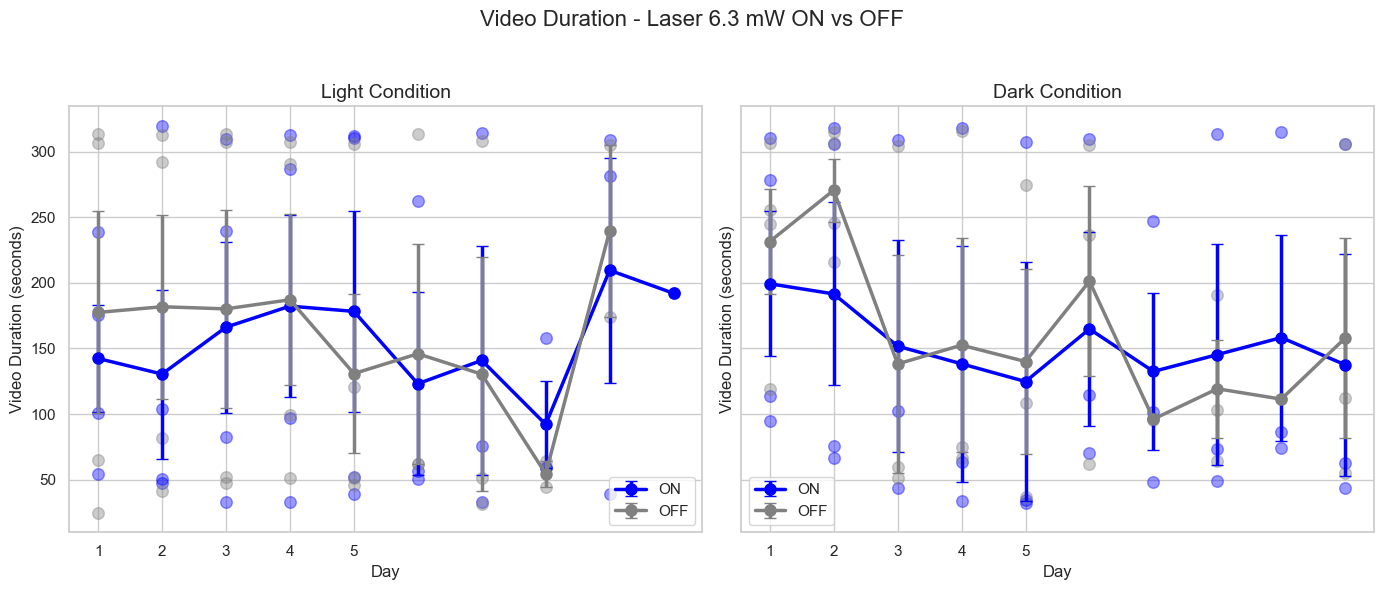

In [242]:
plot_duration_comparison(gad2_df_cleaned, "Video Duration")

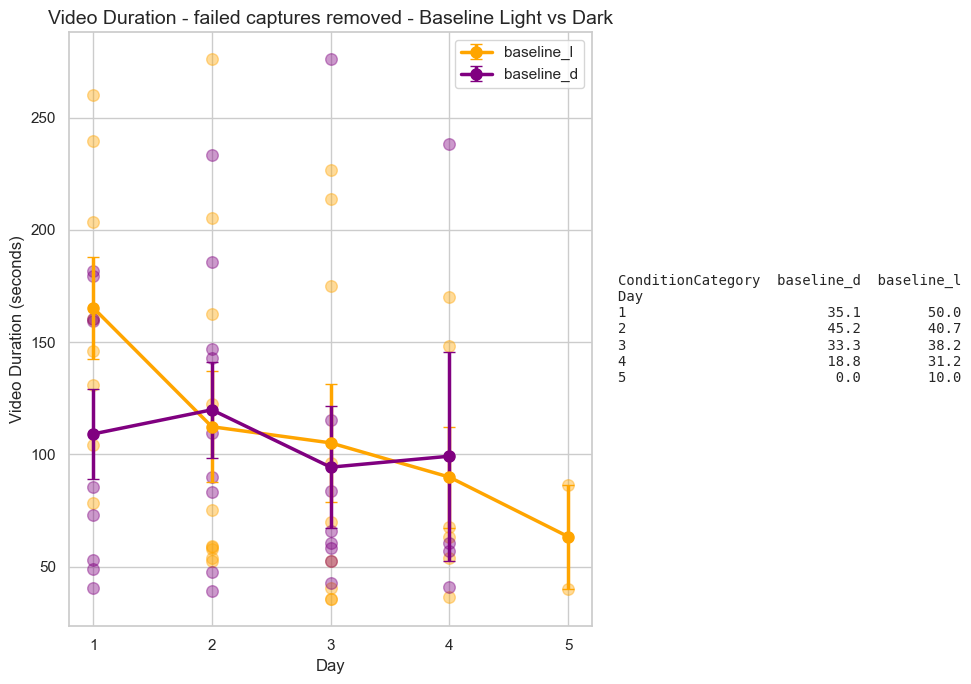

/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


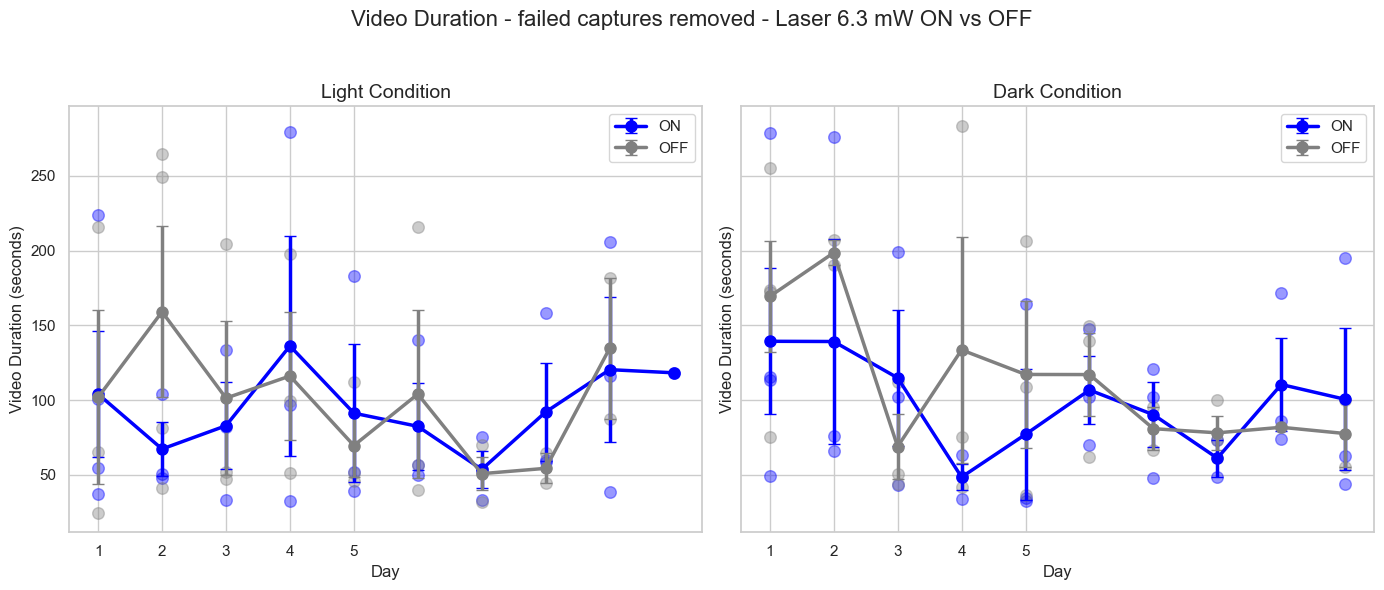

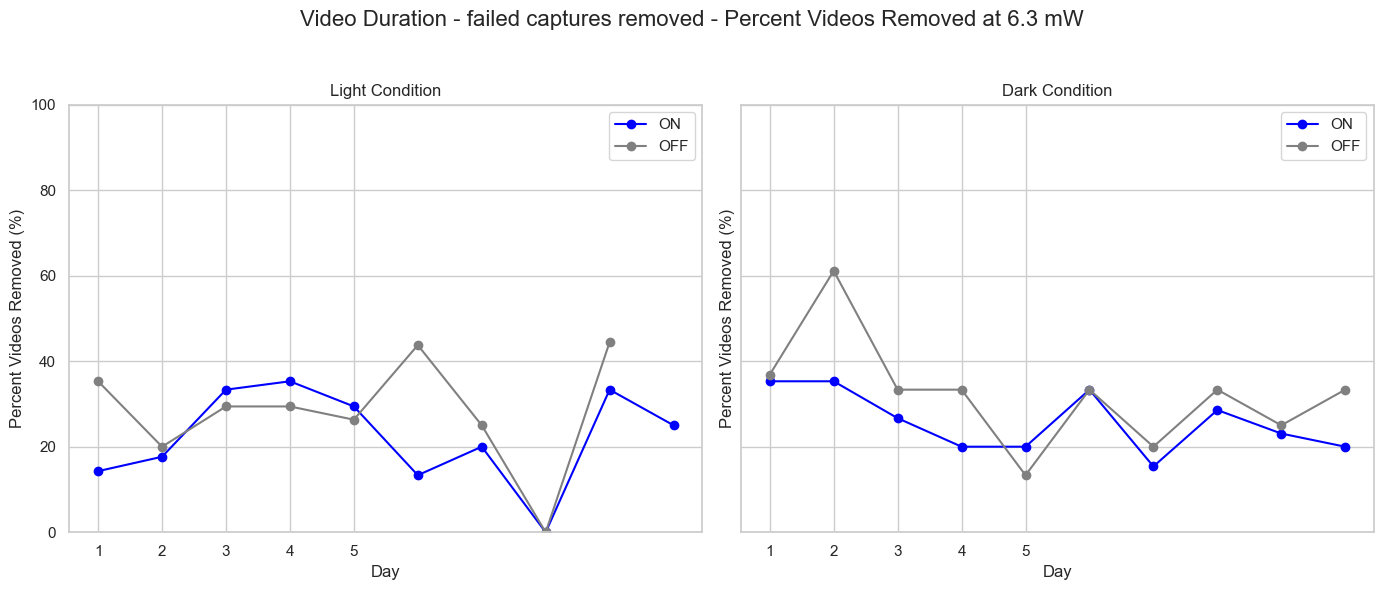

No data for power 3.5 mW


In [243]:
plot_duration_and_removal_comparison(gad2_df_cleaned, "Video Duration - failed captures removed")

In [239]:
# Ensure VideoDuration is numeric
gad2_df['Duration_sec'] = pd.to_numeric(gad2_df['Duration_sec'], errors='coerce')

# Filter rows with VideoDuration > 300 seconds
# Filter for long videos and specific condition categories
filtered_df = gad2_df[
    (gad2_df['Duration_sec'] > 400) &
    (gad2_df['ConditionCategory'].isin(['baseline_l', 'baseline_d']))
]
# Display results
print(filtered_df[['Mouse', 'Date', 'ConditionCategory', 'Duration_sec']])


       Mouse       Date ConditionCategory  Duration_sec
1486  3276.0 2025-04-23        baseline_l       1846.74
2144  3278.0 2025-04-23        baseline_l       1810.73


In [241]:
import numpy as np

# Ensure Duration_sec is numeric
gad2_df_cleaned['Duration_sec'] = pd.to_numeric(gad2_df_cleaned['Duration_sec'], errors='coerce')

# Define the mask for rows to update
mask = (
    (gad2_df_cleaned['Duration_sec'] > 400) &
    (gad2_df_cleaned['ConditionCategory'].isin(['baseline_l', 'baseline_d']))
)

# Set ConditionCategory to NaN where mask is True
gad2_df_cleaned.loc[mask, 'ConditionCategory'] = np.nan

# Optional: check how many were changed
print(f"Updated {mask.sum()} rows to have NaN as ConditionCategory.")


Updated 2 rows to have NaN as ConditionCategory.
